## 1. Merge the datasets

Our training data contains the sales target and basic identifiers, but useful predictive information is stored in separate files.

Our goal is to create one dataset containing sales and the features that may help predict them.

In [1]:
import pandas as pd

train = pd.read_csv("../data/raw/train.csv")
features = pd.read_csv("../data/raw/features.csv")
stores = pd.read_csv("../data/raw/stores.csv")

print("Train:", train.shape)
print("Features:", features.shape)
print("Stores:", stores.shape)

Train: (421570, 5)
Features: (8190, 12)
Stores: (45, 3)


### Merge the features into the training data

In [2]:

train["Date"] = pd.to_datetime(train["Date"])
features["Date"] = pd.to_datetime(features["Date"])

sales_features = train.merge(
    features,
    on=["Store", "Date"],
    how="left",
    suffixes=("", "_feature")
)

print("Before merge:", train.shape)
print("After merge:", sales_features.shape)


Before merge: (421570, 5)
After merge: (421570, 15)


### Merge the store dataset

In [3]:
sales_features = sales_features.merge(
    stores,
    on="Store",
    how="left",
    validate="many_to_one"
)

print("Shape after store merge:", sales_features.shape)
sales_features.head()


Shape after store merge: (421570, 17)


,Store,Dept,Date,Weekly_Sales,IsHoliday,Temperature,Fuel_Price,MarkDown1,MarkDown2,MarkDown3,MarkDown4,MarkDown5,CPI,Unemployment,IsHoliday_feature,Type,Size
0,1,1,2010-02-05,24924.50,False,42.31,2.572,NaN,NaN,NaN,NaN,NaN,211.096358,8.106,False,A,151315
1,1,1,2010-02-12,46039.49,True,38.51,2.548,NaN,NaN,NaN,NaN,NaN,211.242170,8.106,True,A,151315
2,1,1,2010-02-19,41595.55,False,39.93,2.514,NaN,NaN,NaN,NaN,NaN,211.289143,8.106,False,A,151315
3,1,1,2010-02-26,19403.54,False,46.63,2.561,NaN,NaN,NaN,NaN,NaN,211.319643,8.106,False,A,151315
4,1,1,2010-03-05,21827.90,False,46.50,2.625,NaN,NaN,NaN,NaN,NaN,211.350143,8.106,False,A,151315


#### Checking whether the merge introduced missing values

In [4]:
print("Missing values in merged dataset:")
print(sales_features.isnull().sum().sort_values(ascending=False).head(12))

Missing values in merged dataset:
MarkDown2       310322
MarkDown4       286603
MarkDown3       284479
MarkDown1       270889
MarkDown5       270138
Store                0
IsHoliday            0
Dept                 0
Date                 0
Temperature          0
Fuel_Price           0
Weekly_Sales         0
dtype: int64


In [5]:
missing_summary = pd.DataFrame({
    "missing_count": sales_features.isnull().sum(),
    "missing_percent": (
        sales_features.isnull().mean() * 100
    ).round(2),
    "data_type": sales_features.dtypes.astype(str)
})

missing_summary = missing_summary.sort_values(
    "missing_percent",
    ascending=False
)

missing_summary

,missing_count,missing_percent,data_type
MarkDown2,310322,73.61,float64
MarkDown4,286603,67.98,float64
MarkDown3,284479,67.48,float64
MarkDown1,270889,64.26,float64
MarkDown5,270138,64.08,float64
Store,0,0.00,int64
IsHoliday,0,0.00,bool
Dept,0,0.00,int64
Date,0,0.00,datetime64[us]
Temperature,0,0.00,float64


Why are the markdown values missing?

The original Walmart dataset documentation explains that markdown data is available only after November 2011 and is not available for all stores at all times. 

So, at least some missing values are expected because the markdown features were not recorded throughout the entire dataset.

Our next step is to check the dates associated with missing markdown values before deciding how to handle them.

In [6]:

markdown_cols = [
    "MarkDown1",
    "MarkDown2",
    "MarkDown3",
    "MarkDown4",
    "MarkDown5"
]

markdown_missing_by_year = (
    sales_features
    .assign(Year=sales_features["Date"].dt.year)
    .groupby("Year")[markdown_cols]
    .agg(lambda column: column.isnull().mean() * 100)
    .round(2)
)

markdown_missing_by_year


,MarkDown1,MarkDown2,MarkDown3,MarkDown4,MarkDown5
Year,,,,,
2010,100.00,100.00,100.00,100.00,100.00
2011,84.56,86.87,84.94,86.29,84.36
2012,0.36,28.52,10.56,10.60,0.00


In [7]:

markdown_cols = [
    "MarkDown1",
    "MarkDown2",
    "MarkDown3",
    "MarkDown4",
    "MarkDown5"
]

for col in markdown_cols:
    available_dates = sales_features.loc[
        sales_features[col].notna(), "Date"
    ]

    print(
        f"{col}:",
        available_dates.min(),
        "to",
        available_dates.max()
    )


MarkDown1: 2011-11-11 00:00:00 to 2012-10-26 00:00:00
MarkDown2: 2011-11-11 00:00:00 to 2012-10-26 00:00:00
MarkDown3: 2011-11-11 00:00:00 to 2012-10-26 00:00:00
MarkDown4: 2011-11-11 00:00:00 to 2012-10-26 00:00:00
MarkDown5: 2011-11-11 00:00:00 to 2012-10-26 00:00:00


In [8]:

markdown_cols = [
    "MarkDown1",
    "MarkDown2",
    "MarkDown3",
    "MarkDown4",
    "MarkDown5"
]

# Flag whether the markdown information is available
sales_features["Markdown_Data_Available"] = (
    sales_features[markdown_cols]
    .notna()
    .any(axis=1)
)

print(
    sales_features["Markdown_Data_Available"]
    .value_counts()
)

print(
    sales_features.groupby("Markdown_Data_Available")["Date"]
    .agg(["min", "max"])
)


Markdown_Data_Available
False    270138
True     151432
Name: count, dtype: int64
                               min        max
Markdown_Data_Available                      
False                   2010-02-05 2011-11-04
True                    2011-11-11 2012-10-26


In [9]:

print("Dataset shape:", sales_features.shape)

print(
    "Duplicate Store-Date-Dept records:",
    sales_features.duplicated(
        subset=["Store", "Date", "Dept"]
    ).sum()
)

print(
    "Missing store types:",
    sales_features["Type"].isna().sum()
)

print(
    "Missing store sizes:",
    sales_features["Size"].isna().sum()
)

print(
    "Holiday flags agree:",
    sales_features["IsHoliday"].equals(
        sales_features["IsHoliday_feature"]
    )
)


Dataset shape: (421570, 18)
Duplicate Store-Date-Dept records: 0
Missing store types: 0
Missing store sizes: 0
Holiday flags agree: True


## 2. Create calendar features

Our Date column contains dates such as 2011-12-23. A machine learning model may benefit from having that date broken into meaningful components.

In [10]:

sales_features["Year"] = sales_features["Date"].dt.year

sales_features["Month"] = sales_features["Date"].dt.month

sales_features["WeekOfYear"] = (
    sales_features["Date"].dt.isocalendar().week.astype(int)
)

sales_features["Quarter"] = sales_features["Date"].dt.quarter

sales_features[
    ["Date", "Year", "Month", "WeekOfYear", "Quarter"]
].head(10)


,Date,Year,Month,WeekOfYear,Quarter
0,2010-02-05,2010,2,5,1
1,2010-02-12,2010,2,6,1
2,2010-02-19,2010,2,7,1
3,2010-02-26,2010,2,8,1
4,2010-03-05,2010,3,9,1
5,2010-03-12,2010,3,10,1
6,2010-03-19,2010,3,11,1
7,2010-03-26,2010,3,12,1
8,2010-04-02,2010,4,13,2
9,2010-04-09,2010,4,14,2


## 3. Create training and validation datasets

### Choose a validation period

Our training data runs from February 5, 2010, to October 26, 2012.

Let's reserve the last 12 recorded weeks as our initial validation period. This lets us evaluate predictions on dates later than the training period.

In [11]:
all_dates = sorted(sales_features["Date"].unique())

validation_dates = all_dates[-12:]

validation_start = validation_dates[0]

print("Validation starts:", validation_start)
print("Validation ends:", validation_dates[-1])
print("Number of validation weeks:", len(validation_dates))

Validation starts: 2012-08-10 00:00:00
Validation ends: 2012-10-26 00:00:00
Number of validation weeks: 12


### Split the data

In [12]:
train_data = sales_features[
    sales_features["Date"] < validation_start
].copy()

validation_data = sales_features[
    sales_features["Date"] >= validation_start
].copy()

print("Training shape:", train_data.shape)
print("Validation shape:", validation_data.shape)

print(
    "Training dates:",
    train_data["Date"].min(),
    "to",
    train_data["Date"].max()
)

print(
    "Validation dates:",
    validation_data["Date"].min(),
    "to",
    validation_data["Date"].max()
)

Training shape: (386007, 22)
Validation shape: (35563, 22)
Training dates: 2010-02-05 00:00:00 to 2012-08-03 00:00:00
Validation dates: 2012-08-10 00:00:00 to 2012-10-26 00:00:00


In [13]:

print(
    "Overlapping dates:",
    len(
        set(train_data["Date"].unique())
        & set(validation_data["Date"].unique())
    )
)

print(
    "Training ends before validation:",
    train_data["Date"].max() < validation_data["Date"].min()
)


Overlapping dates: 0
Training ends before validation: True


Our split is correct, but it doesn't guarantee that every store–department combination has enough historical observations to support a forecast. We'll investigate that when we establish our baseline.

Also, the last 12 weeks are a validation window, not the final test dataset. We'll keep test.csv separate until we are ready to generate predictions.

#### Verify the chronological split

In [14]:
print(
    "Overlapping dates:",
    len(
        set(train_data["Date"].unique())
        & set(validation_data["Date"].unique())
    )
)

print(
    "Training ends before validation:",
    train_data["Date"].max() < validation_data["Date"].min()
)


Overlapping dates: 0
Training ends before validation: True


## 4. Establishing a baseline

Before using machine learning, we need a simple model to compare against. This is called a baseline model.

Our first baseline will be the last-observed-sales baseline: for each Store–Department combination, predict that its sales in the validation period will remain equal to its most recent observed sales in the training period.

For example, if Store 1, Department 1 last recorded weekly sales of ₹20,000 in the training data, our baseline predicts ₹20,000 for each of its validation weeks.

This is deliberately simple. Later, we can check whether more advanced models actually improve on it.

### 4.1. Find the last recorded sales for each Store–Department pair

In [15]:
# Sort records from oldest to newest
train_sorted = train_data.sort_values("Date")

# Keep the most recent training sales for each Store–Department pair
last_sales = (
    train_sorted
    .drop_duplicates(subset=["Store", "Dept"], keep="last")
    [["Store", "Dept", "Weekly_Sales"]]
    .rename(columns={"Weekly_Sales": "Baseline_Prediction"})
)

print("Store–Department pairs:", len(last_sales))
last_sales.head()

Store–Department pairs: 3322


,Store,Dept,Baseline_Prediction
328433,34,78,3.00
345101,36,85,6.48
133636,14,43,0.25
173227,18,48,10.00
47131,5,78,6.00


### 4.2. Attach these predictions to the validation data

In [16]:
validation_predictions = validation_data.merge(
    last_sales,
    on=["Store", "Dept"],
    how="left",
    validate="many_to_one"
)

print(
    "Validation rows without a baseline prediction:",
    validation_predictions["Baseline_Prediction"].isna().sum()
)

validation_predictions[
    ["Store", "Dept", "Date", "Weekly_Sales", "Baseline_Prediction"]
].head(10)


Validation rows without a baseline prediction: 22


,Store,Dept,Date,Weekly_Sales,Baseline_Prediction
0,1,1,2012-08-10,16119.92,16628.31
1,1,1,2012-08-17,17330.70,16628.31
2,1,1,2012-08-24,16286.40,16628.31
3,1,1,2012-08-31,16680.24,16628.31
4,1,1,2012-09-07,18322.37,16628.31
5,1,1,2012-09-14,19616.22,16628.31
6,1,1,2012-09-21,19251.50,16628.31
7,1,1,2012-09-28,18947.81,16628.31
8,1,1,2012-10-05,21904.47,16628.31
9,1,1,2012-10-12,22764.01,16628.31


For Store 1, Department 1, the model uses the last training observation of 16,628.31 and repeats it across the validation weeks. Actual sales change from week to week, but our baseline stays constant. This gives us a simple benchmark for measuring whether more sophisticated models can capture the changes.

One important detail: you have 3,322 Store–Department pairs in training, compared with 3,331 in the original dataset. Some combinations have no training history before the validation period, so we need to check whether any validation rows are missing predictions.

### 4.3. Check for missing baseline predictions

In [17]:
missing_predictions = validation_predictions[
    "Baseline_Prediction"
].isna().sum()

total_validation_rows = len(validation_predictions)

print("Missing predictions:", missing_predictions)
print("Total validation rows:", total_validation_rows)
print(
    "Percentage missing:",
    round(missing_predictions / total_validation_rows * 100, 2),
    "%"
)

Missing predictions: 22
Total validation rows: 35563
Percentage missing: 0.06 %


#### 4.3.1. Handle the missing predictions

For these 22 rows, we'll use the median training sales for the same department as a fallback. This is a reasonable starting point because the department's typical sales provide some information when a particular Store–Department combination has no prior history.

We will calculate these medians from train_data only, so we don't use future validation sales to build the predictions.

In [18]:
# Calculate the median sales for each department using training data
department_medians = train_data.groupby("Dept")["Weekly_Sales"].median()

# Fill missing baseline predictions using the department median
missing_mask = validation_predictions["Baseline_Prediction"].isna()

validation_predictions.loc[missing_mask, "Baseline_Prediction"] = (
    validation_predictions.loc[missing_mask, "Dept"]
    .map(department_medians)
)

print(
    "Missing predictions after fallback:",
    validation_predictions["Baseline_Prediction"].isna().sum()
)

Missing predictions after fallback: 0


### 4.4. Evaluate the baseline model

In [19]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

actual = validation_predictions["Weekly_Sales"]
predicted = validation_predictions["Baseline_Prediction"]

mae = mean_absolute_error(actual, predicted)
rmse = np.sqrt(mean_squared_error(actual, predicted))

print(f"Baseline MAE: {mae:.2f}")
print(f"Baseline RMSE: {rmse:.2f}")


Baseline MAE: 2301.15
Baseline RMSE: 5066.83


- MAE = 2,301.15: across the validation rows, the predictions differ from actual weekly sales by an average absolute amount of about 2,301.15.



- RMSE = 5,066.83: the larger RMSE suggests that some predictions have substantially larger errors than others.



- The baseline repeats the last available sales value, so it cannot independently capture changing trends, seasonal patterns, or holiday effects during the 12-week validation period.

## 5. Seasonal-naïve forecasting model

### 5.1. Create the seasonal predictions

In [20]:
# Keep the validation records and create a date 52 weeks earlier
seasonal_predictions = validation_data[
    ["Store", "Dept", "Date", "Weekly_Sales"]
].copy()

seasonal_predictions["Previous_Year_Date"] = (
    seasonal_predictions["Date"] - pd.Timedelta(weeks=52)
)

# Prepare historical sales for matching
historical_sales = train_data[
    ["Store", "Dept", "Date", "Weekly_Sales"]
].rename(
    columns={
        "Date": "Previous_Year_Date",
        "Weekly_Sales": "Seasonal_Prediction"
    }
)

# Match each validation row with sales from 52 weeks earlier
seasonal_predictions = seasonal_predictions.merge(
    historical_sales,
    on=["Store", "Dept", "Previous_Year_Date"],
    how="left",
    validate="many_to_one"
)

print(
    "Missing seasonal predictions:",
    seasonal_predictions["Seasonal_Prediction"].isna().sum()
)

seasonal_predictions[
    [
        "Store", "Dept", "Date",
        "Weekly_Sales", "Previous_Year_Date",
        "Seasonal_Prediction"
    ]
].head(10)


Missing seasonal predictions: 835


,Store,Dept,Date,Weekly_Sales,Previous_Year_Date,Seasonal_Prediction
0,1,1,2012-08-10,16119.92,2011-08-12,14539.79
1,1,1,2012-08-17,17330.70,2011-08-19,14689.24
2,1,1,2012-08-24,16286.40,2011-08-26,14537.37
3,1,1,2012-08-31,16680.24,2011-09-02,15277.27
4,1,1,2012-09-07,18322.37,2011-09-09,17746.68
5,1,1,2012-09-14,19616.22,2011-09-16,18535.48
6,1,1,2012-09-21,19251.50,2011-09-23,17859.30
7,1,1,2012-09-28,18947.81,2011-09-30,18337.68
8,1,1,2012-10-05,21904.47,2011-10-07,20797.58
9,1,1,2012-10-12,22764.01,2011-10-14,23077.55


### 5.2. Handle missing matches and evaluate the model

In [21]:
# Attach the existing baseline as a fallback
seasonal_predictions = seasonal_predictions.merge(
    validation_predictions[
        ["Store", "Dept", "Date", "Baseline_Prediction"]
    ],
    on=["Store", "Dept", "Date"],
    how="left",
    validate="one_to_one"
)

# Use the previous-year value when available; otherwise use the fallback
seasonal_predictions["Seasonal_Prediction"] = (
    seasonal_predictions["Seasonal_Prediction"].fillna(
        seasonal_predictions["Baseline_Prediction"]
    )
)

# Evaluate seasonal-naive performance
actual = seasonal_predictions["Weekly_Sales"]
predicted = seasonal_predictions["Seasonal_Prediction"]

from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

print(
    "Missing predictions after fallback:",
    predicted.isna().sum()
)

print(f"Seasonal Naive MAE: {mean_absolute_error(actual, predicted):.2f}")
print(f"Seasonal Naive RMSE: {np.sqrt(mean_squared_error(actual, predicted)):.2f}")


Missing predictions after fallback: 0
Seasonal Naive MAE: 1680.60
Seasonal Naive RMSE: 3627.51


In [22]:
baseline_results = pd.DataFrame({
    "Model": [
        "Last Observed Sales",
        "Seasonal Naive (52 Weeks)"
    ],
    "MAE": [
        2301.15,
        1680.60
    ],
    "RMSE": [
        5066.83,
        3627.51
    ]
})

baseline_results


,Model,MAE,RMSE
0,Last Observed Sales,2301.15,5066.83
1,Seasonal Naive (52 Weeks),1680.60,3627.51


## 6. Prepare features for machine learning

### 6.1. Select the features

In [23]:
feature_cols = [
    "Store",
    "Dept",
    "IsHoliday",
    "Year",
    "Month",
    "WeekOfYear",
    "Quarter",
    "Temperature",
    "Fuel_Price",
    "CPI",
    "Unemployment",
    "Type",
    "Size"
]

X_train = train_data[feature_cols].copy()
y_train = train_data["Weekly_Sales"].copy()

X_validation = validation_data[feature_cols].copy()
y_validation = validation_data["Weekly_Sales"].copy()

print("X_train shape:", X_train.shape)
print("y_train shape:", y_train.shape)
print("X_validation shape:", X_validation.shape)
print("y_validation shape:", y_validation.shape)

X_train.head()

X_train shape: (386007, 13)
y_train shape: (386007,)
X_validation shape: (35563, 13)
y_validation shape: (35563,)


,Store,Dept,IsHoliday,Year,Month,WeekOfYear,Quarter,Temperature,Fuel_Price,CPI,Unemployment,Type,Size
0,1,1,False,2010,2,5,1,42.31,2.572,211.096358,8.106,A,151315
1,1,1,True,2010,2,6,1,38.51,2.548,211.242170,8.106,A,151315
2,1,1,False,2010,2,7,1,39.93,2.514,211.289143,8.106,A,151315
3,1,1,False,2010,2,8,1,46.63,2.561,211.319643,8.106,A,151315
4,1,1,False,2010,3,9,1,46.50,2.625,211.350143,8.106,A,151315


### 6.2. Encode the categorical feature

In [24]:
# Convert Store Type into numerical indicator columns
X_train_encoded = pd.get_dummies(
    X_train,
    columns=["Type"],
    dtype=int
)

X_validation_encoded = pd.get_dummies(
    X_validation,
    columns=["Type"],
    dtype=int
)

# Ensure both datasets have exactly the same feature columns
X_validation_encoded = X_validation_encoded.reindex(
    columns=X_train_encoded.columns,
    fill_value=0
)

print("Encoded training shape:", X_train_encoded.shape)
print("Encoded validation shape:", X_validation_encoded.shape)

X_train_encoded.head()


Encoded training shape: (386007, 15)
Encoded validation shape: (35563, 15)


,Store,Dept,IsHoliday,Year,Month,WeekOfYear,Quarter,Temperature,Fuel_Price,CPI,Unemployment,Size,Type_A,Type_B,Type_C
0,1,1,False,2010,2,5,1,42.31,2.572,211.096358,8.106,151315,1,0,0
1,1,1,True,2010,2,6,1,38.51,2.548,211.242170,8.106,151315,1,0,0
2,1,1,False,2010,2,7,1,39.93,2.514,211.289143,8.106,151315,1,0,0
3,1,1,False,2010,2,8,1,46.63,2.561,211.319643,8.106,151315,1,0,0
4,1,1,False,2010,3,9,1,46.50,2.625,211.350143,8.106,151315,1,0,0


## 7. HistGradientBoostingRegressor

In [25]:
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

# Create the model
model = HistGradientBoostingRegressor(
    max_iter=100,
    learning_rate=0.1,
    max_leaf_nodes=31,
    random_state=42
)

# Learn patterns from training data only
model.fit(X_train_encoded, y_train)

# Predict sales for the validation period
ml_predictions = model.predict(X_validation_encoded)

# Evaluate the predictions
ml_mae = mean_absolute_error(y_validation, ml_predictions)
ml_rmse = np.sqrt(mean_squared_error(y_validation, ml_predictions))

print(f"Machine Learning MAE: {ml_mae:.2f}")
print(f"Machine Learning RMSE: {ml_rmse:.2f}")


Machine Learning MAE: 3796.83
Machine Learning RMSE: 6124.25


Why did machine learning perform worse?

Our first model uses store characteristics, calendar information, holidays, and economic variables. However, it doesn't directly know what each Store–Department combination sold in recent weeks or during the corresponding period last year.

That creates three potential problems:
- Missing historical sales signals: recent sales are often highly informative for future sales.
- Limited time-series features: month and week number alone may not capture each department's specific sales pattern.
- Model structure: gradient boosting is a useful starting point, but its performance depends on the features and settings we provide.

We shouldn't conclude that machine learning is unsuitable for this dataset. We should first give it more relevant information.

## 8. HistGradientBoosting + lag features model

Create historical sales features

Our objective is to help the model learn from two sources:

- Recent sales: how much a particular store and department sold in its most recent training week.
- Yearly seasonality: how much it sold around the same time last year.

In [26]:
# Sort the training records chronologically
train_history = train_data.sort_values("Date").copy()

# Find the latest observed sales for each Store–Department pair
last_sales_features = (
    train_history
    .drop_duplicates(subset=["Store", "Dept"], keep="last")
    [["Store", "Dept", "Weekly_Sales"]]
    .rename(
        columns={"Weekly_Sales": "Last_Observed_Sales"}
    )
)

# Find sales from 52 weeks earlier where available
seasonal_sales_features = historical_sales[
    ["Store", "Dept", "Previous_Year_Date", "Seasonal_Prediction"]
].copy()

# Attach the last-observed sales feature to training and validation
X_train_history = X_train_encoded.merge(
    last_sales_features,
    on=["Store", "Dept"],
    how="left",
    validate="many_to_one"
)

X_validation_history = X_validation_encoded.merge(
    last_sales_features,
    on=["Store", "Dept"],
    how="left",
    validate="many_to_one"
)

print("Training features:", X_train_history.shape)
print("Validation features:", X_validation_history.shape)
print(
    "Missing latest-sales features in validation:",
    X_validation_history["Last_Observed_Sales"].isna().sum()
)


Training features: (386007, 16)
Validation features: (35563, 16)
Missing latest-sales features in validation: 22


Build leakage-safe lag features

In [27]:
# Historical sales records, sorted by Store, Department and Date
history = train_data[
    ["Store", "Dept", "Date", "Weekly_Sales"]
].copy()

history = history.sort_values(["Store", "Dept", "Date"])

# Lag 1: previous recorded observation within each series
history["Lag_1"] = (
    history.groupby(["Store", "Dept"])["Weekly_Sales"].shift(1)
)

# Build a lookup for sales exactly 52 weeks before each date
lag52_lookup = history[
    ["Store", "Dept", "Date", "Weekly_Sales"]
].copy()

lag52_lookup["Date"] = (
    lag52_lookup["Date"] + pd.Timedelta(weeks=52)
)

lag52_lookup = lag52_lookup.rename(
    columns={"Weekly_Sales": "Lag_52"}
)

# Attach the matching previous-year sales
history = history.merge(
    lag52_lookup,
    on=["Store", "Dept", "Date"],
    how="left",
    validate="one_to_one"
)

print("Historical rows:", len(history))
print("Lag 1 missing:", history["Lag_1"].isna().sum())
print("Lag 52 missing:", history["Lag_52"].isna().sum())

history[
    ["Store", "Dept", "Date", "Weekly_Sales", "Lag_1", "Lag_52"]
].head(10)


Historical rows: 386007
Lag 1 missing: 3322
Lag 52 missing: 159194


,Store,Dept,Date,Weekly_Sales,Lag_1,Lag_52
0,1,1,2010-02-05,24924.50,NaN,NaN
1,1,1,2010-02-12,46039.49,24924.50,NaN
2,1,1,2010-02-19,41595.55,46039.49,NaN
3,1,1,2010-02-26,19403.54,41595.55,NaN
4,1,1,2010-03-05,21827.90,19403.54,NaN
5,1,1,2010-03-12,21043.39,21827.90,NaN
6,1,1,2010-03-19,22136.64,21043.39,NaN
7,1,1,2010-03-26,26229.21,22136.64,NaN
8,1,1,2010-04-02,57258.43,26229.21,NaN
9,1,1,2010-04-09,42960.91,57258.43,NaN


In [28]:

print("Lag 1 available (%):",
      round(history["Lag_1"].notna().mean() * 100, 2))

print("Lag 52 available (%):",
      round(history["Lag_52"].notna().mean() * 100, 2))

print(
    "Rows with both lags available:",
    history[["Lag_1", "Lag_52"]].notna().all(axis=1).sum()
)


Lag 1 available (%): 99.14
Lag 52 available (%): 58.76
Rows with both lags available: 226813


 Prepare the training features

In [29]:
# Keep the historical lag features and their matching keys
lag_features = history[
    ["Store", "Dept", "Date", "Lag_1", "Lag_52"]
].copy()

# Add Date to the encoded training features using the original row index
X_train_lagged = X_train_encoded.copy()
X_train_lagged["Date"] = train_data["Date"].values

# Merge the lag features onto the training rows
X_train_lagged = X_train_lagged.merge(
    lag_features,
    on=["Store", "Dept", "Date"],
    how="left",
    validate="one_to_one"
)

print("Training feature shape:", X_train_lagged.shape)
print("Missing Lag_1:", X_train_lagged["Lag_1"].isna().sum())
print("Missing Lag_52:", X_train_lagged["Lag_52"].isna().sum())

X_train_lagged.head()



Training feature shape: (386007, 18)
Missing Lag_1: 3322
Missing Lag_52: 159194


,Store,Dept,IsHoliday,Year,Month,WeekOfYear,Quarter,Temperature,Fuel_Price,CPI,Unemployment,Size,Type_A,Type_B,Type_C,Date,Lag_1,Lag_52
0,1,1,False,2010,2,5,1,42.31,2.572,211.096358,8.106,151315,1,0,0,2010-02-05,NaN,NaN
1,1,1,True,2010,2,6,1,38.51,2.548,211.242170,8.106,151315,1,0,0,2010-02-12,24924.50,NaN
2,1,1,False,2010,2,7,1,39.93,2.514,211.289143,8.106,151315,1,0,0,2010-02-19,46039.49,NaN
3,1,1,False,2010,2,8,1,46.63,2.561,211.319643,8.106,151315,1,0,0,2010-02-26,41595.55,NaN
4,1,1,False,2010,3,9,1,46.50,2.625,211.350143,8.106,151315,1,0,0,2010-03-05,19403.54,NaN


Create the model's training dataset

In [30]:
# Get the names of the existing model features
base_features = X_train_encoded.columns.tolist()

# Copy the encoded predictors
train_predictors = X_train_encoded.copy()

# Add Date so we can match each row to its historical sales
train_predictors["Date"] = train_data["Date"].to_numpy()

# Attach Lag_1 and Lag_52 using Store, Dept, and Date
lag_features = history[
    ["Store", "Dept", "Date", "Lag_1", "Lag_52"]
].copy()

lagged_training_data = train_predictors.merge(
    lag_features,
    on=["Store", "Dept", "Date"],
    how="left",
    validate="one_to_one"
)

# Select model features, excluding Date and Weekly_Sales
lag_feature_cols = base_features + ["Lag_1", "Lag_52"]

X_lag_train = lagged_training_data[lag_feature_cols].copy()
y_lag_train = train_data["Weekly_Sales"].copy()

print("Training features shape:", X_lag_train.shape)
print("Training target shape:", y_lag_train.shape)
print("\nMissing lag values:")
print(X_lag_train[["Lag_1", "Lag_52"]].isna().sum())



Training features shape: (386007, 17)
Training target shape: (386007,)

Missing lag values:
Lag_1       3322
Lag_52    159194
dtype: int64


Train the lag-based forecasting model

In [31]:
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

# Create the forecasting model
lag_model = HistGradientBoostingRegressor(
    max_iter=100,
    learning_rate=0.1,
    max_leaf_nodes=31,
    random_state=42
)

# Learn the relationship between features and weekly sales
lag_model.fit(X_lag_train, y_lag_train)

print("Lag-based model training completed!")


Lag-based model training completed!


Generate recursive validation predictions

In [32]:

# Last known sales for each Store-Dept combination
last_known_sales = (
    train_data.sort_values("Date")
    .drop_duplicates(["Store", "Dept"], keep="last")
    .set_index(["Store", "Dept"])["Weekly_Sales"]
    .to_dict()
)

# Historical actual sales, used only for the 52-week lag
historical_sales = train_data.set_index(
    ["Store", "Dept", "Date"]
)["Weekly_Sales"].to_dict()

validation_sorted = validation_data.sort_values("Date").copy()
recursive_predictions = []

for current_date in sorted(validation_sorted["Date"].unique()):

    week_data = validation_sorted[
        validation_sorted["Date"] == current_date
    ].copy()

    # Create Lag_1 from the latest available actual or predicted sales
    week_data["Lag_1"] = [
        last_known_sales.get((store, dept), np.nan)
        for store, dept in zip(week_data["Store"], week_data["Dept"])
    ]

    # Create Lag_52 from actual sales 52 weeks earlier
    previous_year_date = current_date - pd.Timedelta(weeks=52)

    week_data["Lag_52"] = [
        historical_sales.get((store, dept, previous_year_date), np.nan)
        for store, dept in zip(week_data["Store"], week_data["Dept"])
    ]

    # Apply the same one-hot encoding used during model training
    X_week_base = pd.get_dummies(
        week_data[feature_cols],
        columns=["Type"],
        dtype=int
    )

    # Match training columns exactly; absent categories become zero
    X_week_base = X_week_base.reindex(
        columns=X_train_encoded.columns,
        fill_value=0
    )

    # Add lag features in the same order used during training
    X_week_base["Lag_1"] = week_data["Lag_1"].to_numpy()
    X_week_base["Lag_52"] = week_data["Lag_52"].to_numpy()

    X_week = X_week_base[
        X_lag_train.columns
    ]

    # Predict this week's sales
    week_predictions = lag_model.predict(X_week)

    week_data["Predicted_Sales"] = week_predictions

    recursive_predictions.append(
        week_data[["Store", "Dept", "Date", "Predicted_Sales"]]
    )

    # Update history using predictions, never actual validation sales
    for store, dept, prediction in zip(
        week_data["Store"],
        week_data["Dept"],
        week_predictions
    ):
        last_known_sales[(store, dept)] = prediction

lag_validation_predictions = pd.concat(
    recursive_predictions,
    ignore_index=True
)

print("Validation predictions:", len(lag_validation_predictions))
print(
    "Missing predictions:",
    lag_validation_predictions["Predicted_Sales"].isna().sum()
)

display(lag_validation_predictions.head())


Validation predictions: 35563
Missing predictions: 0


,Store,Dept,Date,Predicted_Sales
0,1,1,2012-08-10,16340.579339
1,17,59,2012-08-10,327.030220
2,17,58,2012-08-10,2091.533812
3,17,56,2012-08-10,695.668829
4,17,55,2012-08-10,5450.725221


Evaluate the lag-based model

In [33]:

# Match predictions with the actual validation sales
lag_evaluation = validation_data[
    ["Store", "Dept", "Date", "Weekly_Sales"]
].merge(
    lag_validation_predictions,
    on=["Store", "Dept", "Date"],
    how="left",
    validate="one_to_one"
)

# Calculate Mean Absolute Error
lag_mae = mean_absolute_error(
    lag_evaluation["Weekly_Sales"],
    lag_evaluation["Predicted_Sales"]
)

# Calculate Root Mean Squared Error
lag_rmse = np.sqrt(
    mean_squared_error(
        lag_evaluation["Weekly_Sales"],
        lag_evaluation["Predicted_Sales"]
    )
)

print(f"Lag-based Model MAE:  ${lag_mae:,.2f}")
print(f"Lag-based Model RMSE: ${lag_rmse:,.2f}")


Lag-based Model MAE:  $1,679.22
Lag-based Model RMSE: $3,396.77


Improving the forecasting model

Residual analysis

In [34]:
# Create a copy so we preserve the original evaluation data
residual_analysis = lag_evaluation.copy()

# Calculate prediction errors
residual_analysis["Residual"] = (
    residual_analysis["Weekly_Sales"]
    - residual_analysis["Predicted_Sales"]
)

# Calculate absolute errors
residual_analysis["Absolute_Error"] = (
    residual_analysis["Residual"].abs()
)

# Display the key results
display(
    residual_analysis[
        [
            "Store",
            "Dept",
            "Date",
            "Weekly_Sales",
            "Predicted_Sales",
            "Residual",
            "Absolute_Error"
        ]
    ].head(10)
)


,Store,Dept,Date,Weekly_Sales,Predicted_Sales,Residual,Absolute_Error
0,1,1,2012-08-10,16119.92,16340.579339,-220.659339,220.659339
1,1,1,2012-08-17,17330.70,16334.575159,996.124841,996.124841
2,1,1,2012-08-24,16286.40,16279.010973,7.389027,7.389027
3,1,1,2012-08-31,16680.24,16334.575159,345.664841,345.664841
4,1,1,2012-09-07,18322.37,17386.493043,935.876957,935.876957
5,1,1,2012-09-14,19616.22,17919.069888,1697.150112,1697.150112
6,1,1,2012-09-21,19251.50,17861.239390,1390.260610,1390.260610
7,1,1,2012-09-28,18947.81,17936.669257,1011.140743,1011.140743
8,1,1,2012-10-05,21904.47,19346.889207,2557.580793,2557.580793
9,1,1,2012-10-12,22764.01,21336.401252,1427.608748,1427.608748


examine the overall residuals

In [35]:
print("Mean residual:", round(residual_analysis["Residual"].mean(), 2))
print("Median residual:", round(residual_analysis["Residual"].median(), 2))
print("Mean absolute error:", round(residual_analysis["Absolute_Error"].mean(), 2))

print("\nResidual distribution:")
display(residual_analysis["Residual"].describe())

Mean residual: -167.82
Median residual: -138.68
Mean absolute error: 1679.22

Residual distribution:


count    35563.000000
mean      -167.820894
std       3392.666579
min     -60518.727573
25%       -915.446774
50%       -138.676285
75%        554.665191
max      72830.600632
Name: Residual, dtype: float64

Find where the model makes its biggest mistakes

,Store,Dept,Date,Weekly_Sales,Predicted_Sales,Residual,Absolute_Error
9906,13,3,2012-09-07,114230.60,41399.999368,72830.600632,72830.600632
12528,16,9,2012-10-19,111246.19,43396.221254,67849.968746,67849.968746
11390,14,72,2012-10-19,69389.31,129908.037573,-60518.727573,60518.727573
11391,14,72,2012-10-26,63071.17,119882.736453,-56811.566453,56811.566453
7385,10,3,2012-08-17,60619.61,112880.211760,-52260.601760,52260.601760
11490,14,90,2012-08-24,85339.29,136625.966586,-51286.676586,51286.676586
23215,28,92,2012-09-07,153061.49,105065.015825,47996.474175,47996.474175
8012,10,72,2012-08-31,96347.84,143180.553142,-46832.713142,46832.713142
8020,10,72,2012-10-26,121126.83,167863.573023,-46736.743023,46736.743023
8019,10,72,2012-10-19,101213.23,146834.739044,-45621.509044,45621.509044


Five weeks with the highest MAE:


,Date,Actual_Sales,Predicted_Sales,MAE,Mean_Residual,Total_Sales_Error
11,2012-10-26,45544116.29,4.752093e+07,1934.235270,-668.067733,-1.976812e+06
10,2012-10-19,45122410.57,4.708542e+07,1863.575950,-665.425388,-1.963005e+06
8,2012-10-05,47566639.31,4.718606e+07,1835.765681,127.883322,3.805808e+05
9,2012-10-12,46128514.25,4.637280e+07,1818.076992,-81.699773,-2.442823e+05
7,2012-09-28,43734899.40,4.390718e+07,1765.112637,-58.163229,-1.722795e+05


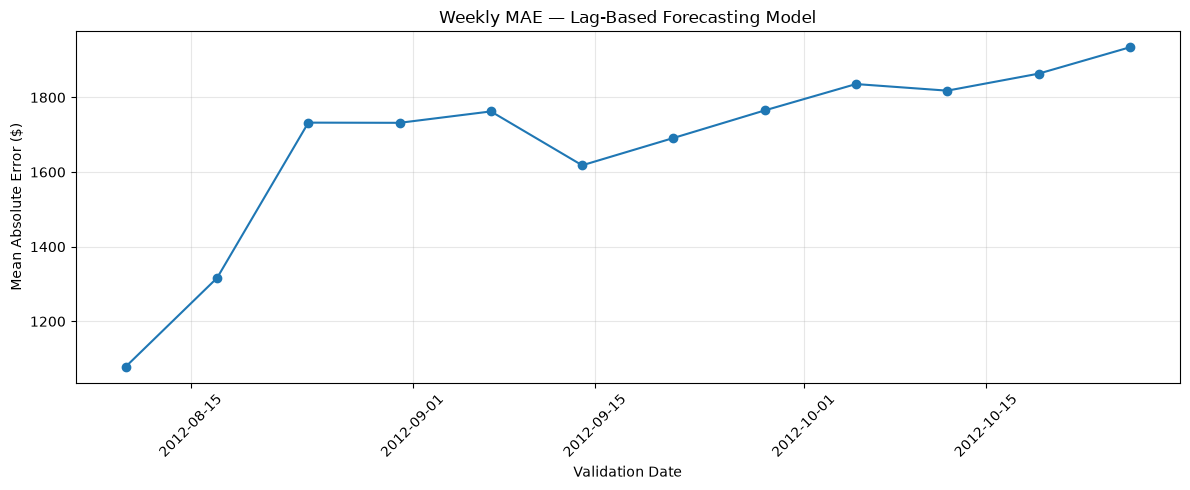

In [36]:

# 1. Find the 10 largest absolute prediction errors
largest_errors = residual_analysis.nlargest(
    10, "Absolute_Error"
)[
    [
        "Store",
        "Dept",
        "Date",
        "Weekly_Sales",
        "Predicted_Sales",
        "Residual",
        "Absolute_Error"
    ]
]

display(largest_errors)

# 2. Summarize prediction errors by validation week
weekly_errors = (
    residual_analysis
    .groupby("Date")
    .agg(
        Actual_Sales=("Weekly_Sales", "sum"),
        Predicted_Sales=("Predicted_Sales", "sum"),
        MAE=("Absolute_Error", "mean"),
        Mean_Residual=("Residual", "mean")
    )
    .reset_index()
)

weekly_errors["Total_Sales_Error"] = (
    weekly_errors["Actual_Sales"]
    - weekly_errors["Predicted_Sales"]
)

print("Five weeks with the highest MAE:")
display(
    weekly_errors
    .nlargest(5, "MAE")
)

# 3. Plot weekly MAE
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))
plt.plot(
    weekly_errors["Date"],
    weekly_errors["MAE"],
    marker="o"
)
plt.title("Weekly MAE — Lag-Based Forecasting Model")
plt.xlabel("Validation Date")
plt.ylabel("Mean Absolute Error ($)")
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


C:\Users\markr\AppData\Local\Temp\ipykernel_15408\4105092592.py:14: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  ].round(2)


,Forecast_Week,Date,MAE,Mean_Residual,Total_Sales_Error
0,1,2012-08-10,1078.69,20.49,60602.36
1,2,2012-08-17,1316.26,-46.02,-135986.60
2,3,2012-08-24,1732.40,-101.89,-301583.09
3,4,2012-08-31,1731.91,8.92,26415.88
4,5,2012-09-07,1762.42,198.14,587686.11
5,6,2012-09-14,1618.06,-614.25,-1822485.90
6,7,2012-09-21,1691.24,-137.57,-407064.87
7,8,2012-09-28,1765.11,-58.16,-172279.48
8,9,2012-10-05,1835.77,127.88,380580.77
9,10,2012-10-12,1818.08,-81.70,-244282.32


First-week MAE: $1,078.69
Last-week MAE:  $1,934.24
MAE change: 79.31%


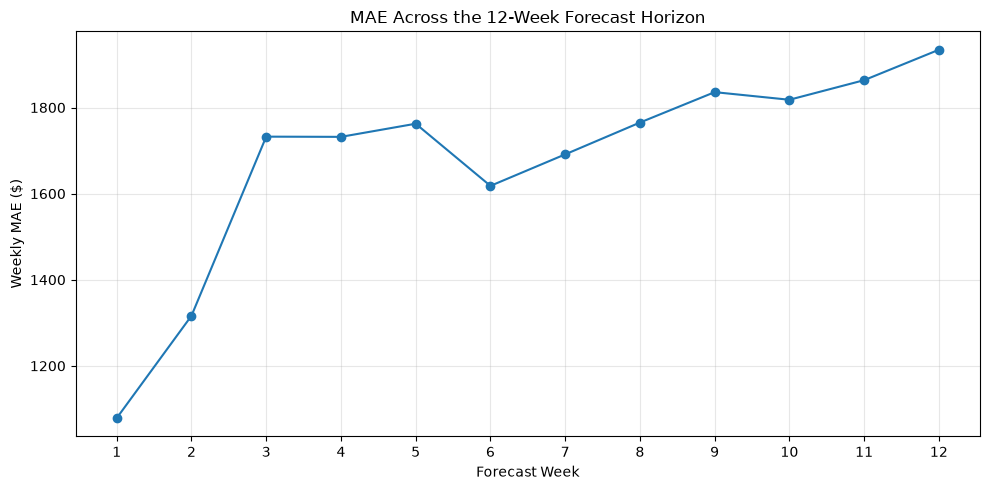

In [37]:

# Sort weeks chronologically
weekly_errors = weekly_errors.sort_values("Date").reset_index(drop=True)

# Add forecast week number: 1 to 12
weekly_errors["Forecast_Week"] = np.arange(
    1, len(weekly_errors) + 1
)

# Display the complete weekly error trend
display(
    weekly_errors[
        ["Forecast_Week", "Date", "MAE", "Mean_Residual",
         "Total_Sales_Error"]
    ].round(2)
)

# Compare first-week and last-week MAE
first_week_mae = weekly_errors.iloc[0]["MAE"]
last_week_mae = weekly_errors.iloc[-1]["MAE"]

mae_change_pct = (
    (last_week_mae - first_week_mae) / first_week_mae
) * 100

print(f"First-week MAE: ${first_week_mae:,.2f}")
print(f"Last-week MAE:  ${last_week_mae:,.2f}")
print(f"MAE change: {mae_change_pct:.2f}%")

# Visualize MAE over the forecast horizon
plt.figure(figsize=(10, 5))
plt.plot(
    weekly_errors["Forecast_Week"],
    weekly_errors["MAE"],
    marker="o"
)
plt.title("MAE Across the 12-Week Forecast Horizon")
plt.xlabel("Forecast Week")
plt.ylabel("Weekly MAE ($)")
plt.xticks(range(1, len(weekly_errors) + 1))
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


Investigate which departments cause the largest errors

In [38]:
# Group validation errors by department
department_errors = (
    residual_analysis
    .groupby("Dept")
    .agg(
        Actual_Sales=("Weekly_Sales", "mean"),
        Predicted_Sales=("Predicted_Sales", "mean"),
        MAE=("Absolute_Error", "mean"),
        Mean_Residual=("Residual", "mean"),
        Number_of_Records=("Weekly_Sales", "size")
    )
    .reset_index()
)

# Show the 10 departments with the highest MAE
department_errors = department_errors.sort_values(
    "MAE", ascending=False
)

display(department_errors.head(10).round(2))


,Dept,Actual_Sales,Predicted_Sales,MAE,Mean_Residual,Number_of_Records
37,39,15.23,20218.52,20203.29,-20203.29,9
56,65,50443.40,36488.90,13954.50,13954.50,12
59,72,44609.13,45120.26,6577.62,-511.13,507
36,38,59298.69,61093.19,6539.81,-1794.50,540
72,92,79447.74,79394.90,5673.71,52.83,540
75,95,71107.29,73984.43,4992.78,-2877.13,540
2,3,18635.84,18999.05,4690.26,-363.21,540
16,18,5650.43,1328.95,4436.58,4321.48,460
70,90,46594.31,48340.23,3491.59,-1745.92,540
71,91,33674.61,35172.36,2968.02,-1497.75,540


compare errors relative to sales volume

In [39]:
# Calculate department-level WAPE using validation predictions
department_wape = (
    residual_analysis
    .groupby("Dept")
    .agg(
        Total_Absolute_Error=("Absolute_Error", "sum"),
        Total_Absolute_Actual=(
            "Weekly_Sales",
            lambda x: x.abs().sum()
        ),
        Number_of_Records=("Weekly_Sales", "size")
    )
    .reset_index()
)

department_wape["WAPE_Percent"] = (
    department_wape["Total_Absolute_Error"]
    / department_wape["Total_Absolute_Actual"]
    * 100
)

# Exclude departments with very few validation records for this comparison
department_wape = department_wape[
    department_wape["Number_of_Records"] >= 100
]

department_wape = department_wape.sort_values(
    "WAPE_Percent", ascending=False
)

display(department_wape.head(10).round(2).to_string(index=False))


' Dept  Total_Absolute_Error  Total_Absolute_Actual  Number_of_Records  WAPE_Percent\n   54             130881.50               12392.41                336       1056.14\n   99              95465.51               18662.81                179        511.53\n   59             143258.88               97101.78                474        147.53\n   60             147758.25              166191.41                540         88.91\n   18            2040825.95             2599265.77                460         78.52\n   36             321903.60              420026.33                444         76.64\n   48             240035.52              412576.99                174         58.18\n   31             680021.21             1443986.22                526         47.09\n   56             322127.34              705699.71                503         45.65\n   58             695989.28             1678715.55                368         41.46'

inspect the worst departments

In [40]:

# Inspect the worst-performing departments
worst_departments = [54, 99]

department_detail = residual_analysis[
    residual_analysis["Dept"].isin(worst_departments)
].copy()

# Summarize actual and predicted sales
department_summary = (
    department_detail
    .groupby("Dept")
    .agg(
        Actual_Mean=("Weekly_Sales", "mean"),
        Actual_Median=("Weekly_Sales", "median"),
        Actual_Min=("Weekly_Sales", "min"),
        Actual_Max=("Weekly_Sales", "max"),
        Predicted_Mean=("Predicted_Sales", "mean"),
        MAE=("Absolute_Error", "mean"),
        Mean_Residual=("Residual", "mean"),
        Negative_Actuals=(
            "Weekly_Sales",
            lambda x: (x < 0).sum()
        ),
        Zero_Actuals=(
            "Weekly_Sales",
            lambda x: (x == 0).sum()
        ),
        Records=("Weekly_Sales", "size")
    )
    .reset_index()
)

display(department_summary.round(2).to_string(index=False))


' Dept  Actual_Mean  Actual_Median  Actual_Min  Actual_Max  Predicted_Mean    MAE  Mean_Residual  Negative_Actuals  Zero_Actuals  Records\n   54        33.92          28.92     -233.00      311.72          422.86 389.53        -388.94                13             2      336\n   99       104.26          20.12        0.01     1320.12          624.18 533.33        -519.91                 0             0      179'

In [41]:

# Inspect actual and predicted sales for Departments 54 and 99
for dept in [54, 99]:
    print(f"\nDepartment {dept}")

    dept_data = residual_analysis[
        residual_analysis["Dept"] == dept
    ].copy()

    print("\nSales distribution:")
    display(
        dept_data[
            ["Weekly_Sales", "Predicted_Sales", "Absolute_Error"]
        ].describe().round(2)
    )

    print("\nFive largest prediction errors:")
    display(
        dept_data.nlargest(5, "Absolute_Error")[
            ["Store", "Date", "Weekly_Sales",
             "Predicted_Sales", "Residual", "Absolute_Error"]
        ].round(2).to_string(index=False)
    )



Department 54

Sales distribution:


,Weekly_Sales,Predicted_Sales,Absolute_Error
count,336.00,336.00,336.00
mean,33.92,422.86,389.53
std,41.07,272.64,273.99
min,-233.00,96.08,33.44
25%,10.57,203.72,171.43
50%,28.92,336.80,318.19
75%,44.80,581.12,537.53
max,311.72,1613.58,1593.06



Five largest prediction errors:


C:\Users\markr\AppData\Local\Temp\ipykernel_15408\2465448184.py:21: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  ].round(2).to_string(index=False)


' Store       Date  Weekly_Sales  Predicted_Sales  Residual  Absolute_Error\n     4 2012-10-26         20.52          1613.58  -1593.06         1593.06\n     4 2012-10-19         23.92          1342.22  -1318.30         1318.30\n    13 2012-10-26         16.88          1167.33  -1150.45         1150.45\n    28 2012-10-26         28.80          1150.96  -1122.16         1122.16\n     6 2012-10-26         34.80          1152.60  -1117.80         1117.80'


Department 99

Sales distribution:


,Weekly_Sales,Predicted_Sales,Absolute_Error
count,179.00,179.00,179.00
mean,104.26,624.18,533.33
std,225.69,348.54,326.77
min,0.01,107.67,49.90
25%,0.07,367.85,331.08
50%,20.12,501.49,414.29
75%,62.55,800.19,658.42
max,1320.12,2048.60,2018.72



Five largest prediction errors:


C:\Users\markr\AppData\Local\Temp\ipykernel_15408\2465448184.py:21: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  ].round(2).to_string(index=False)


' Store       Date  Weekly_Sales  Predicted_Sales  Residual  Absolute_Error\n    12 2012-09-14         29.88          2048.60  -2018.72         2018.72\n    29 2012-08-24         29.88          1941.66  -1911.78         1911.78\n    21 2012-10-12         29.88          1762.27  -1732.39         1732.39\n    21 2012-08-10         29.88          1626.45  -1596.57         1596.57\n    41 2012-10-26         29.88          1429.13  -1399.25         1399.25'

In [42]:

# Compare training and validation sales for Departments 54 and 99
for dept in [54, 99]:
    print(f"\nDepartment {dept}")

    # Training history
    train_dept = train_data[train_data["Dept"] == dept]

    print("\nTraining sales summary:")
    display(
        train_dept["Weekly_Sales"]
        .describe()
        .round(2)
        .to_frame()
    )

    # Validation actual sales
    validation_dept = validation_data[
        validation_data["Dept"] == dept
    ]

    print("\nValidation sales summary:")
    display(
        validation_dept["Weekly_Sales"]
        .describe()
        .round(2)
        .to_frame()
    )

    # Inspect several historical records
    print("\nLatest training records:")
    display(
        train_dept.sort_values("Date")
        [["Store", "Dept", "Date", "Weekly_Sales"]]
        .tail(10)
        .to_string(index=False)
    )



Department 54

Training sales summary:


,Weekly_Sales
count,4431.00
mean,113.95
std,149.00
min,-465.08
25%,28.92
50%,63.74
75%,141.66
max,1371.00



Validation sales summary:


,Weekly_Sales
count,336.00
mean,33.92
std,41.07
min,-233.00
25%,10.57
50%,28.92
75%,44.80
max,311.72



Latest training records:


' Store  Dept       Date  Weekly_Sales\n     1    54 2012-08-03          8.00\n    29    54 2012-08-03          4.88\n    14    54 2012-08-03         36.80\n    28    54 2012-08-03         30.92\n    15    54 2012-08-03          5.88\n    16    54 2012-08-03          8.00\n    18    54 2012-08-03        130.56\n    26    54 2012-08-03          9.50\n    10    54 2012-08-03         55.80\n    45    54 2012-08-03         23.92'

... (2 outputs left out)


Validation sales summary:


,Weekly_Sales
count,179.00
mean,104.26
std,225.69
min,0.01
25%,0.07
50%,20.12
75%,62.55
max,1320.12



Latest training records:


' Store  Dept       Date  Weekly_Sales\n    34    99 2012-08-03        100.01\n    24    99 2012-08-03        100.00\n     6    99 2012-08-03         20.00\n    39    99 2012-08-03        160.06\n    14    99 2012-08-03        240.02\n     4    99 2012-08-03         30.06\n     1    99 2012-08-03         20.00\n    27    99 2012-08-03        220.04\n    32    99 2012-08-03        160.06\n     2    99 2012-08-03        230.08'

WMAE Comparison Table

In [43]:

import numpy as np
import pandas as pd

# 1. Define the competition-style metric
def weighted_mae(actual, predicted, is_holiday):
    actual = np.asarray(actual)
    predicted = np.asarray(predicted)
    is_holiday = np.asarray(is_holiday, dtype=bool)

    weights = np.where(is_holiday, 5.0, 1.0)

    return np.sum(weights * np.abs(actual - predicted)) / np.sum(weights)


# 2. Start with the actual validation records
wmae_results = validation_data[
    ["Store", "Dept", "Date", "Weekly_Sales", "IsHoliday"]
].copy()

# 3. Attach each model's predictions to the same records
wmae_results = wmae_results.merge(
    validation_predictions[
        ["Store", "Dept", "Date", "Baseline_Prediction"]
    ],
    on=["Store", "Dept", "Date"],
    how="left",
    validate="one_to_one"
)

wmae_results = wmae_results.merge(
    seasonal_predictions[
        ["Store", "Dept", "Date", "Seasonal_Prediction"]
    ],
    on=["Store", "Dept", "Date"],
    how="left",
    validate="one_to_one"
)

wmae_results = wmae_results.merge(
    lag_validation_predictions[
        ["Store", "Dept", "Date", "Predicted_Sales"]
    ],
    on=["Store", "Dept", "Date"],
    how="left",
    validate="one_to_one"
)

# 4. Check for missing predictions before scoring
prediction_cols = [
    "Baseline_Prediction",
    "Seasonal_Prediction",
    "Predicted_Sales"
]

print("Missing predictions:")
print(wmae_results[prediction_cols].isna().sum())

# 5. Calculate WMAE and ordinary MAE for comparison
if wmae_results[prediction_cols].isna().any().any():
    raise ValueError("Missing predictions found. Fix them before scoring.")

actual = wmae_results["Weekly_Sales"]
holiday = wmae_results["IsHoliday"]

model_scores = []

for model_name, prediction_col in [
    ("Last Observed", "Baseline_Prediction"),
    ("Seasonal Naive (52 Weeks)", "Seasonal_Prediction"),
    ("Lag-based HistGradientBoosting", "Predicted_Sales")
]:
    predicted = wmae_results[prediction_col]

    model_scores.append({
        "Model": model_name,
        "MAE": np.mean(np.abs(actual - predicted)),
        "WMAE": weighted_mae(actual, predicted, holiday)
    })

wmae_comparison = pd.DataFrame(model_scores)
display(wmae_comparison.round(2))


Missing predictions:
Baseline_Prediction    0
Seasonal_Prediction    0
Predicted_Sales        0
dtype: int64


,Model,MAE,WMAE
0,Last Observed,2301.15,2234.02
1,Seasonal Naive (52 Weeks),1680.60,1706.34
2,Lag-based HistGradientBoosting,1679.22,1700.03


Build a validation window that tests holiday demand

In [44]:
# Inspect the dates available for a holiday-focused backtest
all_dates = pd.DatetimeIndex(
    sales_features["Date"].drop_duplicates().sort_values()
)

cutoff_date = pd.Timestamp("2011-10-28")
validation_start = pd.Timestamp("2011-11-04")
validation_end = validation_start + pd.Timedelta(weeks=38)

print("Training cutoff:", cutoff_date.date())
print("Validation start:", validation_start.date())
print("Validation end:", validation_end.date())
print("Validation weeks:", len(
    all_dates[
        (all_dates >= validation_start) &
        (all_dates <= validation_end)
    ]
))

# Inspect holiday weeks within the proposed validation window
holiday_dates = (
    sales_features.loc[
        (sales_features["Date"] >= validation_start) &
        (sales_features["Date"] <= validation_end) &
        sales_features["IsHoliday"],
        ["Date", "IsHoliday"]
    ]
    .drop_duplicates()
    .sort_values("Date")
)

print("\nHoliday weeks in the proposed validation window:")
display(holiday_dates.to_string(index=False))


Training cutoff: 2011-10-28
Validation start: 2011-11-04
Validation end: 2012-07-27
Validation weeks: 39

Holiday weeks in the proposed validation window:


'      Date  IsHoliday\n2011-11-25       True\n2011-12-30       True\n2012-02-10       True'

Create the 39-week backtest datasets

In [45]:

# Define the 39-week historical backtest
backtest_start = pd.Timestamp("2011-11-04")
backtest_end = pd.Timestamp("2012-07-27")

backtest_train = sales_features[
    sales_features["Date"] < backtest_start
].copy()

backtest_validation = sales_features[
    (sales_features["Date"] >= backtest_start) &
    (sales_features["Date"] <= backtest_end)
].copy()

# Verify the split
print("Training period:")
print(backtest_train["Date"].min().date(),
      "to", backtest_train["Date"].max().date())

print("\nValidation period:")
print(backtest_validation["Date"].min().date(),
      "to", backtest_validation["Date"].max().date())

print("\nTraining rows:", len(backtest_train))
print("Validation rows:", len(backtest_validation))
print("Validation weeks:",
      backtest_validation["Date"].nunique())

# Ensure training and validation dates do not overlap
print("\nOverlapping dates:",
      len(set(backtest_train["Date"]) &
          set(backtest_validation["Date"])))


Training period:
2010-02-05 to 2011-10-28

Validation period:
2011-11-04 to 2012-07-27

Training rows: 267184
Validation rows: 115856
Validation weeks: 39

Overlapping dates: 0


Evaluate a 52-week seasonal-naïve baseline

In [46]:
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error

# 1. Prepare historical sales from the training period only
seasonal_history = backtest_train[
    ["Store", "Dept", "Date", "Weekly_Sales"]
].copy()

# Rename Date so it can match the corresponding date in the validation data
seasonal_history = seasonal_history.rename(
    columns={
        "Date": "Previous_Year_Date",
        "Weekly_Sales": "Seasonal_Prediction"
    }
)

# 2. For each validation row, identify the date 52 weeks earlier
backtest_predictions = backtest_validation[
    ["Store", "Dept", "Date", "Weekly_Sales", "IsHoliday"]
].copy()

backtest_predictions["Previous_Year_Date"] = (
    backtest_predictions["Date"] - pd.Timedelta(weeks=52)
)

# 3. Match each validation row with sales from 52 weeks earlier
backtest_predictions = backtest_predictions.merge(
    seasonal_history,
    on=["Store", "Dept", "Previous_Year_Date"],
    how="left",
    validate="many_to_one"
)

# 4. Prepare the last available sales observation for each Store-Dept
last_observed = (
    backtest_train
    .sort_values("Date")
    .drop_duplicates(["Store", "Dept"], keep="last")
    [["Store", "Dept", "Weekly_Sales"]]
    .rename(columns={"Weekly_Sales": "Last_Observed_Prediction"})
)

backtest_predictions = backtest_predictions.merge(
    last_observed,
    on=["Store", "Dept"],
    how="left",
    validate="many_to_one"
)

# Use last observed sales when the 52-week value is unavailable
backtest_predictions["Seasonal_Prediction"] = (
    backtest_predictions["Seasonal_Prediction"]
    .fillna(backtest_predictions["Last_Observed_Prediction"])
)

# 5. Final fallback: department median calculated from training data only
department_medians = backtest_train.groupby("Dept")["Weekly_Sales"].median()

backtest_predictions["Seasonal_Prediction"] = (
    backtest_predictions["Seasonal_Prediction"]
    .fillna(backtest_predictions["Dept"].map(department_medians))
)

# 6. Verify that every validation row has a prediction
print("Validation rows:", len(backtest_predictions))
print(
    "Missing predictions:",
    backtest_predictions["Seasonal_Prediction"].isna().sum()
)

# 7. Calculate evaluation metrics
actual = backtest_predictions["Weekly_Sales"].to_numpy()
predicted = backtest_predictions["Seasonal_Prediction"].to_numpy()
holiday = backtest_predictions["IsHoliday"].to_numpy(dtype=bool)

mae = mean_absolute_error(actual, predicted)
rmse = np.sqrt(mean_squared_error(actual, predicted))

# Kaggle-style weighted MAE: holiday observations receive 5x weight
weights = np.where(holiday, 5.0, 1.0)

wmae = (
    np.sum(weights * np.abs(actual - predicted))
    / np.sum(weights)
)

print(f"\n39-week Seasonal Naive MAE:  ${mae:,.2f}")
print(f"39-week Seasonal Naive RMSE: ${rmse:,.2f}")
print(f"39-week Seasonal Naive WMAE: ${wmae:,.2f}")

Validation rows: 115856
Missing predictions: 0

39-week Seasonal Naive MAE:  $1,963.47
39-week Seasonal Naive RMSE: $4,323.95
39-week Seasonal Naive WMAE: $2,043.61


Check holiday performance and fallback usage

In [47]:
# A. Compare errors on holiday vs non-holiday rows
backtest_predictions["Absolute_Error"] = (
    backtest_predictions["Weekly_Sales"]
    - backtest_predictions["Seasonal_Prediction"]
).abs()

holiday_performance = (
    backtest_predictions
    .groupby("IsHoliday")
    .agg(
        Rows=("Weekly_Sales", "size"),
        MAE=("Absolute_Error", "mean")
    )
    .reset_index()
)

print("Performance by holiday status:")
print(holiday_performance.to_string(index=False))


# B. Audit how often each prediction fallback was needed
fallback_audit = backtest_validation[
    ["Store", "Dept", "Date"]
].copy()

fallback_audit["Previous_Year_Date"] = (
    fallback_audit["Date"] - pd.Timedelta(weeks=52)
)

# Check whether an exact 52-week observation exists
fallback_audit = fallback_audit.merge(
    seasonal_history,
    on=["Store", "Dept", "Previous_Year_Date"],
    how="left",
    validate="many_to_one"
)

fallback_audit["Exact_Seasonal_Available"] = (
    fallback_audit["Seasonal_Prediction"].notna()
)

# Check whether a last-observed fallback exists
fallback_audit = fallback_audit.merge(
    last_observed,
    on=["Store", "Dept"],
    how="left",
    validate="many_to_one"
)

fallback_audit["Last_Observed_Available"] = (
    fallback_audit["Last_Observed_Prediction"].notna()
)

exact_count = fallback_audit["Exact_Seasonal_Available"].sum()
last_count = (
    ~fallback_audit["Exact_Seasonal_Available"]
    & fallback_audit["Last_Observed_Available"]
).sum()
median_count = (
    ~fallback_audit["Exact_Seasonal_Available"]
    & ~fallback_audit["Last_Observed_Available"]
).sum()

print("\nPrediction source:")
print(f"Exact 52-week observation: {exact_count:,}")
print(f"Last-observed fallback:    {last_count:,}")
print(f"Department-median fallback:{median_count:,}")

Performance by holiday status:
 IsHoliday   Rows         MAE
     False 106831 1934.974404
      True   9025 2300.812806

Prediction source:
Exact 52-week observation: 112,333
Last-observed fallback:    3,110
Department-median fallback:413


Test whether machine learning can beat the baseline

In [48]:
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np
import pandas as pd

# 1. Encode features using the same columns as the original model
X_bt_train = pd.get_dummies(
    backtest_train[feature_cols],
    columns=["Type"],
    dtype=int
).reindex(columns=base_features, fill_value=0)

X_bt_validation = pd.get_dummies(
    backtest_validation[feature_cols],
    columns=["Type"],
    dtype=int
).reindex(columns=base_features, fill_value=0)

# 2. Create Lag_1 and Lag_52 from training history
bt_history = backtest_train[
    ["Store", "Dept", "Date", "Weekly_Sales"]
].copy()

bt_history = bt_history.sort_values(["Store", "Dept", "Date"])

bt_history["Lag_1"] = (
    bt_history.groupby(["Store", "Dept"])["Weekly_Sales"].shift(1)
)

lag52_lookup = backtest_train[
    ["Store", "Dept", "Date", "Weekly_Sales"]
].copy()

lag52_lookup["Date"] = (
    lag52_lookup["Date"] + pd.Timedelta(weeks=52)
)

lag52_lookup = lag52_lookup.rename(
    columns={"Weekly_Sales": "Lag_52"}
)

bt_history = bt_history.merge(
    lag52_lookup,
    on=["Store", "Dept", "Date"],
    how="left",
    validate="one_to_one"
)

# 3. Add lags to the training features
X_bt_train = X_bt_train.reset_index(drop=True)
bt_history = bt_history.reset_index(drop=True)

X_bt_train["Lag_1"] = bt_history["Lag_1"]
X_bt_train["Lag_52"] = bt_history["Lag_52"]

lag_columns = base_features + ["Lag_1", "Lag_52"]

# 4. Train the model on the backtest training period only
bt_model = HistGradientBoostingRegressor(
    max_iter=100,
    learning_rate=0.1,
    max_leaf_nodes=31,
    random_state=42
)

bt_model.fit(
    X_bt_train[lag_columns],
    backtest_train["Weekly_Sales"]
)

# 5. Set up historical lookups for recursive forecasting
sales_lookup = {
    (row.Store, row.Dept, row.Date): row.Weekly_Sales
    for row in backtest_train[
        ["Store", "Dept", "Date", "Weekly_Sales"]
    ].itertuples(index=False)
}

last_known = (
    bt_history.sort_values("Date")
    .drop_duplicates(["Store", "Dept"], keep="last")
    .set_index(["Store", "Dept"])["Weekly_Sales"]
    .to_dict()
)

# 6. Forecast one validation week at a time
bt_forecasts = []

for date in sorted(backtest_validation["Date"].unique()):
    week_mask = backtest_validation["Date"].eq(date)

    week_data = backtest_validation.loc[
        week_mask, ["Store", "Dept", "Date"]
    ].copy()

    X_week = X_bt_validation.loc[week_mask].copy()
    X_week = X_week.reset_index(drop=True)

    lag1_values = []
    lag52_values = []

    for row in week_data.itertuples(index=False):
        pair = (row.Store, row.Dept)

        # Latest available sales: actual training value or prior prediction
        lag1_values.append(last_known.get(pair, np.nan))

        # Exact observation from 52 weeks earlier, if available
        previous_year_date = row.Date - pd.Timedelta(weeks=52)
        lag52_values.append(
            sales_lookup.get(
                (row.Store, row.Dept, previous_year_date),
                np.nan
            )
        )

    X_week["Lag_1"] = lag1_values
    X_week["Lag_52"] = lag52_values

    predictions = bt_model.predict(X_week[lag_columns])

    week_data["Predicted_Sales"] = predictions
    bt_forecasts.append(week_data)

    # Update with predictions, never actual validation sales
    for row in week_data.itertuples(index=False):
        last_known[(row.Store, row.Dept)] = row.Predicted_Sales

bt_forecasts = pd.concat(bt_forecasts, ignore_index=True)

# 7. Evaluate the full 39-week forecast
bt_evaluation = backtest_validation[
    ["Store", "Dept", "Date", "Weekly_Sales", "IsHoliday"]
].merge(
    bt_forecasts,
    on=["Store", "Dept", "Date"],
    how="left",
    validate="one_to_one"
)

actual = bt_evaluation["Weekly_Sales"].to_numpy()
predicted = bt_evaluation["Predicted_Sales"].to_numpy()
weights = np.where(bt_evaluation["IsHoliday"].to_numpy(dtype=bool), 5.0, 1.0)

bt_mae = mean_absolute_error(actual, predicted)
bt_rmse = np.sqrt(mean_squared_error(actual, predicted))
bt_wmae = np.sum(weights * np.abs(actual - predicted)) / np.sum(weights)

print("Validation rows:", len(bt_evaluation))
print("Missing predictions:", bt_evaluation["Predicted_Sales"].isna().sum())
print(f"39-week Lag Model MAE:  ${bt_mae:,.2f}")
print(f"39-week Lag Model RMSE: ${bt_rmse:,.2f}")
print(f"39-week Lag Model WMAE: ${bt_wmae:,.2f}")

Validation rows: 115856
Missing predictions: 0
39-week Lag Model MAE:  $2,871.31
39-week Lag Model RMSE: $5,622.65
39-week Lag Model WMAE: $3,113.42


Check how performance changes over the 39 weeks

In [50]:
# Calculate absolute errors for each prediction
bt_evaluation["Absolute_Error"] = (
    bt_evaluation["Weekly_Sales"] - bt_evaluation["Predicted_Sales"]
).abs()

# Summarize performance for each validation week
weekly_performance = (
    bt_evaluation
    .groupby("Date")
    .agg(
        Rows=("Weekly_Sales", "size"),
        MAE=("Absolute_Error", "mean"),
        Actual_Total=("Weekly_Sales", "sum"),
        Predicted_Total=("Predicted_Sales", "sum")
    )
    .reset_index()
)

# Calculate holiday-weighted MAE for each week
weekly_wmae = (
    bt_evaluation
    .assign(
        Weighted_Error=lambda df: (
            df["Absolute_Error"]
            * np.where(df["IsHoliday"], 5.0, 1.0)
        ),
        Weight=lambda df: np.where(df["IsHoliday"], 5.0, 1.0)
    )
    .groupby("Date")
    .agg(
        Weighted_Error=("Weighted_Error", "sum"),
        Total_Weight=("Weight", "sum")
    )
    .reset_index()
)

weekly_performance = weekly_performance.merge(
    weekly_wmae,
    on="Date",
    validate="one_to_one"
)

weekly_performance["WMAE"] = (
    weekly_performance["Weighted_Error"]
    / weekly_performance["Total_Weight"]
)

weekly_performance["Total_Sales_Error"] = (
    weekly_performance["Predicted_Total"]
    - weekly_performance["Actual_Total"]
)

print(
    weekly_performance[
        ["Date", "Rows", "MAE", "WMAE", "Total_Sales_Error"]
    ].round(2).to_string(index=False)
)

print("\nFirst-week MAE:", round(weekly_performance.iloc[0]["MAE"], 2))
print("Last-week MAE:", round(weekly_performance.iloc[-1]["MAE"], 2))

      Date  Rows     MAE    WMAE  Total_Sales_Error
2011-11-04  2954 1646.30 1646.30        -1680863.20
2011-11-11  2965 1873.42 1873.42         -852672.55
2011-11-18  2961 1719.27 1719.27         1121783.29
2011-11-25  3021 5545.00 5545.00        -3546443.59
2011-12-02  2994 3436.93 3436.93         6221170.16
2011-12-09  3010 3349.92 3349.92         5153379.83
2011-12-16  3013 3979.03 3979.03         7443586.24
2011-12-23  3027 5665.20 5665.20         8714654.55
2011-12-30  3003 3581.00 3581.00        -3938697.36
2012-01-06  2973 3437.02 3437.02         1177424.91
2012-01-13  2966 2908.21 2908.21         4800520.43
2012-01-20  2959 2625.75 2625.75         5133361.71
2012-01-27  2952 2909.07 2909.07         7279497.24
2012-02-03  2977 2615.92 2615.92         4028256.34
2012-02-10  3001 2534.49 2534.49          323472.66
2012-02-17  3007 2704.17 2704.17          519322.86
2012-02-24  2961 2271.31 2271.31         2859356.36
2012-03-02  2990 2401.04 2401.04         2865050.18
2012-03-09  

C:\Users\markr\AppData\Local\Temp\ipykernel_15408\1708357780.py:56: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  ].round(2).to_string(index=False)


Compare the two models week by week

In [51]:
# Combine seasonal-naive and ML predictions for the same validation rows
model_weekly_comparison = bt_evaluation[
    ["Store", "Dept", "Date", "Weekly_Sales", "IsHoliday", "Predicted_Sales"]
].merge(
    backtest_predictions[
        ["Store", "Dept", "Date", "Seasonal_Prediction"]
    ],
    on=["Store", "Dept", "Date"],
    how="left",
    validate="one_to_one"
)

# Calculate absolute errors for both models
model_weekly_comparison["ML_Error"] = (
    model_weekly_comparison["Weekly_Sales"]
    - model_weekly_comparison["Predicted_Sales"]
).abs()

model_weekly_comparison["Seasonal_Error"] = (
    model_weekly_comparison["Weekly_Sales"]
    - model_weekly_comparison["Seasonal_Prediction"]
).abs()

# Summarize each model by week
weekly_model_scores = (
    model_weekly_comparison
    .groupby("Date")
    .agg(
        ML_MAE=("ML_Error", "mean"),
        Seasonal_MAE=("Seasonal_Error", "mean"),
        IsHoliday=("IsHoliday", "first")
    )
    .reset_index()
)

weekly_model_scores["ML_minus_Seasonal"] = (
    weekly_model_scores["ML_MAE"]
    - weekly_model_scores["Seasonal_MAE"]
)

print(weekly_model_scores.round(2).to_string(index=False))

print("\nWeeks where ML performed better:",
      (weekly_model_scores["ML_minus_Seasonal"] < 0).sum())

print("Weeks where seasonal naive performed better:",
      (weekly_model_scores["ML_minus_Seasonal"] > 0).sum())

      Date  ML_MAE  Seasonal_MAE  IsHoliday  ML_minus_Seasonal
2011-11-04 1646.30       2118.51      False            -472.20
2011-11-11 1873.42       1780.28      False              93.14
2011-11-18 1719.27       1571.07      False             148.20
2011-11-25 5545.00       2325.74       True            3219.26
2011-12-02 3436.93       1894.08      False            1542.85
2011-12-09 3349.92       2304.57      False            1045.35
2011-12-16 3979.03       2651.89      False            1327.15
2011-12-23 5665.20       3443.42      False            2221.78
2011-12-30 3581.00       2719.83       True             861.17
2012-01-06 3437.02       1791.08      False            1645.95
2012-01-13 2908.21       1481.00      False            1427.21
2012-01-20 2625.75       1386.45      False            1239.30
2012-01-27 2909.07       1416.73      False            1492.34
2012-02-03 2615.92       1817.38      False             798.54
2012-02-10 2534.49       1856.43       True            

C:\Users\markr\AppData\Local\Temp\ipykernel_15408\278354620.py:41: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  print(weekly_model_scores.round(2).to_string(index=False))


These results make the decision much clearer: seasonal naïve is the stronger model for this 39-week backtest.
- Seasonal naïve wins in 38 of 39 weeks.
- The lag-based ML model wins in only 1 week.
- ML loses not only during the holiday weeks but also across most ordinary weeks.
- The gap becomes especially large during November and December 2011.

This suggests the problem is broader than missing holiday features alone. The current recursive model is not using its historical information as effectively as the simple year-over-year benchmark.

Investigate a possible implementation issue before redesigning the model

In [52]:
# Sort the backtest training data chronologically within each series
lag_gap_check = backtest_train[
    ["Store", "Dept", "Date", "Weekly_Sales"]
].sort_values(["Store", "Dept", "Date"]).copy()

# Find the date of the previous recorded observation for each series
lag_gap_check["Previous_Date"] = (
    lag_gap_check.groupby(["Store", "Dept"])["Date"].shift(1)
)

# Calculate the number of days since that observation
lag_gap_check["Gap_Days"] = (
    lag_gap_check["Date"] - lag_gap_check["Previous_Date"]
).dt.days

# Summarize intervals where a previous observation exists
observed_gaps = lag_gap_check.dropna(subset=["Gap_Days"]).copy()

exact_week = observed_gaps["Gap_Days"].eq(7)
longer_gap = observed_gaps["Gap_Days"].gt(7)

print("Training intervals with a previous observation:",
      len(observed_gaps))
print(
    "Exactly 7 days apart:",
    f"{exact_week.sum():,} ({exact_week.mean() * 100:.2f}%)"
)
print(
    "More than 7 days apart:",
    f"{longer_gap.sum():,} ({longer_gap.mean() * 100:.2f}%)"
)

print("\nMost common observation gaps (days):")
print(observed_gaps["Gap_Days"].value_counts().head(10).to_string())

Training intervals with a previous observation: 263930
Exactly 7 days apart: 260,674 (98.77%)
More than 7 days apart: 3,256 (1.23%)

Most common observation gaps (days):
Gap_Days
7.0     260674
14.0      1374
21.0       520
28.0       321
35.0       198
42.0       116
56.0       107
49.0        94
63.0        76
70.0        64


## Direct 52-week ML forecast

In [53]:
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np
import pandas as pd

# 1. Encode the calendar and store features consistently
X_direct_train = pd.get_dummies(
    backtest_train[feature_cols],
    columns=["Type"],
    dtype=int
).reindex(columns=base_features, fill_value=0)

X_direct_validation = pd.get_dummies(
    backtest_validation[feature_cols],
    columns=["Type"],
    dtype=int
).reindex(columns=base_features, fill_value=0)

# 2. Build a lookup of historical sales from the training period
history_lookup = backtest_train[
    ["Store", "Dept", "Date", "Weekly_Sales"]
].copy()

# Move each historical date forward by 52 weeks.
# This makes the sales value joinable to a future date.
history_lookup["Date"] = (
    history_lookup["Date"] + pd.Timedelta(weeks=52)
)

history_lookup = history_lookup.rename(
    columns={"Weekly_Sales": "Lag_52"}
)

# 3. Add the 52-week lag to the training rows
train_lags = backtest_train[
    ["Store", "Dept", "Date"]
].merge(
    history_lookup,
    on=["Store", "Dept", "Date"],
    how="left",
    validate="one_to_one"
)

X_direct_train = X_direct_train.reset_index(drop=True)
train_lags = train_lags.reset_index(drop=True)

X_direct_train["Lag_52"] = train_lags["Lag_52"]

# 4. Add the 52-week lag to validation rows
validation_keys = backtest_validation[
    ["Store", "Dept", "Date"]
].copy()

validation_lags = validation_keys.merge(
    history_lookup,
    on=["Store", "Dept", "Date"],
    how="left",
    validate="one_to_one"
)

# Fallback 1: last recorded sales before validation started
last_sales_lookup = (
    backtest_train.sort_values("Date")
    .drop_duplicates(["Store", "Dept"], keep="last")
    [["Store", "Dept", "Weekly_Sales"]]
    .rename(columns={"Weekly_Sales": "Last_Observed"})
)

validation_lags = validation_lags.merge(
    last_sales_lookup,
    on=["Store", "Dept"],
    how="left",
    validate="many_to_one"
)

validation_lags["Lag_52"] = validation_lags["Lag_52"].fillna(
    validation_lags["Last_Observed"]
)

# Fallback 2: department median from training data
dept_median = backtest_train.groupby("Dept")["Weekly_Sales"].median()

validation_lags["Lag_52"] = validation_lags["Lag_52"].fillna(
    validation_lags["Dept"].map(dept_median)
)

X_direct_validation = X_direct_validation.reset_index(drop=True)
validation_lags = validation_lags.reset_index(drop=True)

X_direct_validation["Lag_52"] = validation_lags["Lag_52"]

# 5. Train the model using historical data only
direct_features = base_features + ["Lag_52"]

direct_model = HistGradientBoostingRegressor(
    max_iter=100,
    learning_rate=0.1,
    max_leaf_nodes=31,
    random_state=42
)

direct_model.fit(
    X_direct_train[direct_features],
    backtest_train["Weekly_Sales"].reset_index(drop=True)
)

# 6. Predict all validation rows directly — no recursive updates
direct_predictions = direct_model.predict(
    X_direct_validation[direct_features]
)

direct_evaluation = backtest_validation[
    ["Store", "Dept", "Date", "Weekly_Sales", "IsHoliday"]
].copy()

direct_evaluation["Predicted_Sales"] = direct_predictions

# 7. Evaluate the results
actual = direct_evaluation["Weekly_Sales"].to_numpy()
predicted = direct_evaluation["Predicted_Sales"].to_numpy()

weights = np.where(
    direct_evaluation["IsHoliday"].to_numpy(dtype=bool),
    5.0,
    1.0
)

direct_mae = mean_absolute_error(actual, predicted)
direct_rmse = np.sqrt(mean_squared_error(actual, predicted))
direct_wmae = (
    np.sum(weights * np.abs(actual - predicted))
    / np.sum(weights)
)

print("Validation rows:", len(direct_evaluation))
print(
    "Missing predictions:",
    direct_evaluation["Predicted_Sales"].isna().sum()
)
print(f"Direct ML MAE:  ${direct_mae:,.2f}")
print(f"Direct ML RMSE: ${direct_rmse:,.2f}")
print(f"Direct ML WMAE: ${direct_wmae:,.2f}")

Validation rows: 115856
Missing predictions: 0
Direct ML MAE:  $2,544.11
Direct ML RMSE: $5,552.92
Direct ML WMAE: $2,810.46


Find out where direct ML still struggles

In [54]:
# 1. Put all three models' predictions into one table
error_comparison = backtest_validation[
    ["Store", "Dept", "Date", "Weekly_Sales", "IsHoliday"]
].copy()

error_comparison = error_comparison.merge(
    backtest_predictions[
        ["Store", "Dept", "Date", "Seasonal_Prediction"]
    ],
    on=["Store", "Dept", "Date"],
    how="left",
    validate="one_to_one"
)

error_comparison = error_comparison.merge(
    bt_forecasts[
        ["Store", "Dept", "Date", "Predicted_Sales"]
    ].rename(columns={"Predicted_Sales": "Recursive_ML"}),
    on=["Store", "Dept", "Date"],
    how="left",
    validate="one_to_one"
)

error_comparison = error_comparison.merge(
    direct_evaluation[
        ["Store", "Dept", "Date", "Predicted_Sales"]
    ].rename(columns={"Predicted_Sales": "Direct_ML"}),
    on=["Store", "Dept", "Date"],
    how="left",
    validate="one_to_one"
)

# 2. Calculate absolute errors for each model
for model in ["Seasonal_Prediction", "Recursive_ML", "Direct_ML"]:
    error_comparison[f"{model}_Error"] = (
        error_comparison["Weekly_Sales"] - error_comparison[model]
    ).abs()

# 3. Compare MAE separately for holiday and non-holiday rows
holiday_comparison = (
    error_comparison
    .groupby("IsHoliday")
    .agg(
        Rows=("Weekly_Sales", "size"),
        Seasonal_MAE=("Seasonal_Prediction_Error", "mean"),
        Recursive_ML_MAE=("Recursive_ML_Error", "mean"),
        Direct_ML_MAE=("Direct_ML_Error", "mean")
    )
    .reset_index()
)

print(holiday_comparison.round(2).to_string(index=False))

 IsHoliday   Rows  Seasonal_MAE  Recursive_ML_MAE  Direct_ML_MAE
     False 106831       1934.97           2785.21        2449.40
      True   9025       2300.81           3890.44        3665.26


- The weakness is not limited to holidays. Direct ML's MAE is about 26.6% higher than seasonal naïve on non-holiday rows and 59.3% higher on holiday rows.
- Holidays are harder for every model. Even the seasonal baseline has higher MAE during holiday weeks.
- Direct ML improves on recursive ML but remains behind the baseline. The simpler forecasting method is still the most reliable of the three tested approaches.

## Seasonal-adjustment model

In [56]:
# 1. Create training data with the sales from 52 weeks earlier
seasonal_train = backtest_train[
    ["Store", "Dept", "Date", "Weekly_Sales"]
].copy()

seasonal_train["Previous_Year_Date"] = (
    seasonal_train["Date"] - pd.Timedelta(weeks=52)
)

previous_sales_train = backtest_train[
    ["Store", "Dept", "Date", "Weekly_Sales"]
].rename(
    columns={
        "Date": "Previous_Year_Date",
        "Weekly_Sales": "Lag_52"
    }
)

seasonal_train = seasonal_train.merge(
    previous_sales_train,
    on=["Store", "Dept", "Previous_Year_Date"],
    how="left",
    validate="many_to_one"
)

seasonal_train = seasonal_train.dropna(subset=["Lag_52"]).copy()

# 2. Predict the change from the previous year's sales
seasonal_train["Sales_Change"] = (
    seasonal_train["Weekly_Sales"] - seasonal_train["Lag_52"]
)

# 3. Build features and attach the target using Store, Dept, and Date
X_change_all = pd.get_dummies(
    backtest_train[feature_cols],
    columns=["Type"],
    dtype=int
).reindex(columns=base_features, fill_value=0)

X_change_all[["Store", "Dept", "Date"]] = (
    backtest_train[["Store", "Dept", "Date"]].to_numpy()
)

change_training_data = X_change_all.merge(
    seasonal_train[["Store", "Dept", "Date", "Sales_Change"]],
    on=["Store", "Dept", "Date"],
    how="inner",
    validate="one_to_one"
)

X_change_train = change_training_data[base_features]
y_change_train = change_training_data["Sales_Change"]

# 4. Train the model
change_model = HistGradientBoostingRegressor(
    max_iter=100,
    learning_rate=0.1,
    max_leaf_nodes=31,
    random_state=42
)

change_model.fit(X_change_train, y_change_train)

print("Training rows with a 52-week reference:", len(change_training_data))
print("Feature rows:", len(X_change_train))
print("Target rows:", len(y_change_train))
print("Features and targets aligned:", len(X_change_train) == len(y_change_train))

Training rows with a 52-week reference: 111618
Feature rows: 111618
Target rows: 111618
Features and targets aligned: True


Evaluate on the 39-week validation period

In [59]:
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error

# 1. Create the previous-year sales lookup from training data only
previous_sales = backtest_train[
    ["Store", "Dept", "Date", "Weekly_Sales"]
].rename(
    columns={
        "Date": "Previous_Year_Date",
        "Weekly_Sales": "Lag_52"
    }
)

# 2. Keep ALL validation columns, including model features
validation_reference = backtest_validation.copy()

validation_reference["Previous_Year_Date"] = (
    validation_reference["Date"] - pd.Timedelta(weeks=52)
)

# 3. Attach the corresponding previous-year sales
validation_reference = validation_reference.merge(
    previous_sales,
    on=["Store", "Dept", "Previous_Year_Date"],
    how="left",
    validate="many_to_one"
)

# 4. Keep rows with a valid previous-year sales reference
covered_validation = validation_reference.dropna(
    subset=["Lag_52"]
).copy()

# 5. Prepare features using the same encoding as training
X_change_validation = pd.get_dummies(
    covered_validation[feature_cols],
    columns=["Type"],
    dtype=int
).reindex(
    columns=base_features,
    fill_value=0
)

# 6. Predict the change from last year's sales
predicted_change = change_model.predict(X_change_validation)

# 7. Calculate final sales forecasts
covered_validation["Predicted_Sales"] = (
    covered_validation["Lag_52"] + predicted_change
)

# 8. Calculate evaluation metrics
actual = covered_validation["Weekly_Sales"].to_numpy()
predicted = covered_validation["Predicted_Sales"].to_numpy()

holiday_flags = covered_validation["IsHoliday"].to_numpy(dtype=bool)
weights = np.where(holiday_flags, 5.0, 1.0)

mae = mean_absolute_error(actual, predicted)
rmse = np.sqrt(mean_squared_error(actual, predicted))
wmae = np.sum(weights * np.abs(actual - predicted)) / np.sum(weights)

# 9. Display results
print("SEASONAL-ADJUSTMENT MODEL — 39-WEEK VALIDATION")
print("-" * 55)
print(f"Total validation rows: {len(backtest_validation):,}")
print(f"Rows evaluated:        {len(covered_validation):,}")
print(
    f"Validation coverage:   "
    f"{len(covered_validation) / len(backtest_validation) * 100:.2f}%"
)
print(f"MAE:                   ${mae:,.2f}")
print(f"RMSE:                  ${rmse:,.2f}")
print(f"WMAE:                  ${wmae:,.2f}")

SEASONAL-ADJUSTMENT MODEL — 39-WEEK VALIDATION
-------------------------------------------------------
Total validation rows: 115,856
Rows evaluated:        112,333
Validation coverage:   96.96%
MAE:                   $2,237.99
RMSE:                  $4,725.02
WMAE:                  $2,291.36


## Error Analysis

In [60]:
import numpy as np
import pandas as pd

# 1. Create predictions from the seasonal-naive baseline
# The baseline simply uses sales from 52 weeks earlier.
covered_validation["Seasonal_Naive_Prediction"] = (
    covered_validation["Lag_52"]
)

# 2. Calculate absolute errors for both models
covered_validation["Naive_Absolute_Error"] = np.abs(
    covered_validation["Weekly_Sales"]
    - covered_validation["Seasonal_Naive_Prediction"]
)

covered_validation["Adjustment_Absolute_Error"] = np.abs(
    covered_validation["Weekly_Sales"]
    - covered_validation["Predicted_Sales"]
)

# 3. Apply Walmart's holiday weighting: holiday weeks count 5 times
weights = np.where(
    covered_validation["IsHoliday"].to_numpy(dtype=bool),
    5.0,
    1.0
)

# 4. Calculate WMAE on exactly the same rows
naive_wmae = np.average(
    covered_validation["Naive_Absolute_Error"],
    weights=weights
)

adjustment_wmae = np.average(
    covered_validation["Adjustment_Absolute_Error"],
    weights=weights
)

improvement = (
    (naive_wmae - adjustment_wmae) / naive_wmae
) * 100

print("FAIR MODEL COMPARISON — SAME VALIDATION ROWS")
print("-" * 55)
print(f"Rows evaluated:              {len(covered_validation):,}")
print(f"Seasonal-naive WMAE:         ${naive_wmae:,.2f}")
print(f"Seasonal-adjustment WMAE:    ${adjustment_wmae:,.2f}")
print(f"Relative improvement:        {improvement:.2f}%")

if improvement > 0:
    print("Result: Seasonal adjustment performs better.")
elif improvement < 0:
    print("Result: Seasonal naive performs better.")
else:
    print("Result: Both models perform equally.")

FAIR MODEL COMPARISON — SAME VALIDATION ROWS
-------------------------------------------------------
Rows evaluated:              112,333
Seasonal-naive WMAE:         $2,064.31
Seasonal-adjustment WMAE:    $2,291.36
Relative improvement:        -11.00%
Result: Seasonal naive performs better.


Find out where the ML model struggles

In [61]:
holiday_analysis = covered_validation.groupby("IsHoliday").agg(
    Rows=("Weekly_Sales", "size"),
    Naive_MAE=("Naive_Absolute_Error", "mean"),
    Adjustment_MAE=("Adjustment_Absolute_Error", "mean")
)

holiday_analysis["MAE_Change"] = (
    holiday_analysis["Naive_MAE"]
    - holiday_analysis["Adjustment_MAE"]
)

holiday_analysis["Improvement_Percent"] = (
    holiday_analysis["MAE_Change"]
    / holiday_analysis["Naive_MAE"]
) * 100

holiday_analysis.index = holiday_analysis.index.map({
    False: "Non-holiday",
    True: "Holiday"
})

display(holiday_analysis.round(2))

,Rows,Naive_MAE,Adjustment_MAE,MAE_Change,Improvement_Percent
IsHoliday,,,,,
Non-holiday,103659,1943.11,2219.07,-275.96,-14.20
Holiday,8674,2353.98,2464.14,-110.16,-4.68


- Historical sales from 52 weeks earlier provide a strong benchmark.
- The seasonal-adjustment model does not improve overall accuracy or either holiday subgroup.
- The model's complexity has not translated into better forecasts on this validation period.

Analyse errors by department

In [62]:
# Compare both models by department
department_analysis = covered_validation.groupby("Dept").agg(
    Rows=("Weekly_Sales", "size"),
    Naive_MAE=("Naive_Absolute_Error", "mean"),
    Adjustment_MAE=("Adjustment_Absolute_Error", "mean")
)

department_analysis["MAE_Change"] = (
    department_analysis["Naive_MAE"]
    - department_analysis["Adjustment_MAE"]
)

department_analysis["Improvement_Percent"] = (
    department_analysis["MAE_Change"]
    / department_analysis["Naive_MAE"]
) * 100

# Sort to find departments where adjustment ML helps most
department_analysis = department_analysis.sort_values(
    "Improvement_Percent",
    ascending=False
)

print("Top 10 departments where adjustment ML performs best:")
display(department_analysis.head(10).round(2))

print("Bottom 10 departments where adjustment ML performs worst:")
display(department_analysis.tail(10).round(2))

Top 10 departments where adjustment ML performs best:


,Rows,Naive_MAE,Adjustment_MAE,MAE_Change,Improvement_Percent
Dept,,,,,
92,1755,7954.09,6517.19,1436.90,18.06
90,1755,3993.72,3636.87,356.85,8.94
87,1749,2488.09,2279.94,208.15,8.37
65,39,8062.36,7542.65,519.71,6.45
82,1755,2232.08,2097.76,134.32,6.02
38,1755,8084.33,7727.60,356.73,4.41
55,1506,2335.48,2288.28,47.21,2.02
93,1600,2920.72,2867.23,53.50,1.83
94,1419,3425.34,3392.29,33.06,0.97


Bottom 10 departments where adjustment ML performs worst:


,Rows,Naive_MAE,Adjustment_MAE,MAE_Change,Improvement_Percent
Dept,,,,,
12,1753,514.03,1082.06,-568.03,-110.50
47,26,359.16,761.64,-402.49,-112.07
27,1498,256.39,621.91,-365.52,-142.57
99,84,369.05,1172.55,-803.50,-217.72
28,1661,116.02,513.04,-397.02,-342.19
60,1608,100.55,529.31,-428.76,-426.42
54,1132,62.88,519.32,-456.44,-725.91
45,219,21.80,476.96,-455.16,-2087.64
51,40,16.63,369.47,-352.83,-2121.28


Results suggest three possibilities:

- Small sales values: When baseline errors are tiny, even a small forecasting mistake can create an enormous percentage deterioration.
- Unreliable adjustments: Adding a predicted year-over-year change can move a good seasonal forecast away from actual sales.
- Limited observations: Departments with very few validation rows cannot be assessed reliably.

Measure how many departments actually benefit

In [63]:
# Keep departments with enough observations for a more useful comparison
reliable_departments = department_analysis[
    department_analysis["Rows"] >= 100
].copy()

# Count departments where the adjustment model wins or loses
improved = reliable_departments["MAE_Change"] > 0
worsened = reliable_departments["MAE_Change"] < 0
unchanged = reliable_departments["MAE_Change"] == 0

print("DEPARTMENT-LEVEL PERFORMANCE SUMMARY")
print("-" * 45)
print(f"Departments evaluated: {len(reliable_departments)}")
print(f"ML improves MAE:       {improved.sum()}")
print(f"ML worsens MAE:        {worsened.sum()}")
print(f"No change:             {unchanged.sum()}")

print("\nLargest absolute MAE improvements:")
display(
    reliable_departments.nlargest(10, "MAE_Change")[
        ["Rows", "Naive_MAE", "Adjustment_MAE",
         "MAE_Change", "Improvement_Percent"]
    ].round(2)
)

print("\nLargest absolute MAE deteriorations:")
display(
    reliable_departments.nsmallest(10, "MAE_Change")[
        ["Rows", "Naive_MAE", "Adjustment_MAE",
         "MAE_Change", "Improvement_Percent"]
    ].round(2)
)

DEPARTMENT-LEVEL PERFORMANCE SUMMARY
---------------------------------------------
Departments evaluated: 73
ML improves MAE:       8
ML worsens MAE:        65
No change:             0

Largest absolute MAE improvements:


,Rows,Naive_MAE,Adjustment_MAE,MAE_Change,Improvement_Percent
Dept,,,,,
92,1755,7954.09,6517.19,1436.90,18.06
90,1755,3993.72,3636.87,356.85,8.94
38,1755,8084.33,7727.60,356.73,4.41
87,1749,2488.09,2279.94,208.15,8.37
82,1755,2232.08,2097.76,134.32,6.02
93,1600,2920.72,2867.23,53.50,1.83
55,1506,2335.48,2288.28,47.21,2.02
94,1419,3425.34,3392.29,33.06,0.97
81,1755,1196.40,1211.03,-14.63,-1.22



Largest absolute MAE deteriorations:


,Rows,Naive_MAE,Adjustment_MAE,MAE_Change,Improvement_Percent
Dept,,,,,
1,1755,4737.96,7172.30,-2434.33,-51.38
72,1641,8214.21,9298.60,-1084.39,-13.20
5,1725,4551.64,5515.47,-963.83,-21.18
16,1755,3144.57,3871.84,-727.27,-23.13
91,1755,2616.92,3326.00,-709.08,-27.10
12,1753,514.03,1082.06,-568.03,-110.50
7,1755,4551.01,5096.97,-545.96,-12.00
18,1342,2506.26,3048.56,-542.29,-21.64
34,1444,2401.19,2938.84,-537.65,-22.39


# Walmart Store Sales Forecasting
## Time Series Analysis, Feature Engineering, and Machine Learning Evaluation

**Project Type:** End-to-end demand forecasting and model evaluation  
**Dataset:** Walmart Recruiting – Store Sales Forecasting  
**Tools:** Python, Pandas, NumPy, Scikit-learn, Matplotlib, Seaborn, Jupyter Notebook  
**Primary Metric:** Weighted Mean Absolute Error (WMAE)

---

## 1. Executive Summary

This project investigates weekly sales forecasting across Walmart stores and departments using historical sales data, store characteristics, calendar information, and economic variables.

The objective was to develop a forecasting workflow, establish baseline performance, evaluate machine learning approaches, and determine whether more complex models could improve on a seasonal forecasting benchmark.

Exploratory data analysis revealed substantial differences in sales across departments, strong seasonal patterns, incomplete historical series, and a small proportion of negative sales observations. A 39-week chronological validation period was subsequently used to compare forecasting strategies, including a seasonal-naïve baseline, direct machine learning, recursive forecasting, and a seasonal-adjustment model.

The seasonal-naïve model produced the best overall performance among the approaches tested. The machine learning models did not consistently improve forecasting accuracy, and department-level analysis showed that the seasonal-adjustment model improved ordinary MAE in only 8 of 73 evaluated departments.

The main conclusion is that historical seasonal patterns provide a strong forecasting benchmark, and additional model complexity must be justified by measurable improvements on an appropriate time-based validation set.

## 2. Business Problem

Retailers need reliable sales forecasts to support inventory planning, replenishment, staffing, and operational decisions.

Inaccurate forecasts can contribute to excess inventory, stockouts, and inefficient resource allocation. The forecasting problem is particularly challenging in retail because demand varies across stores and departments and is influenced by seasonality, holidays, and external economic conditions.

This project addresses the following question:

**Can machine learning improve weekly sales forecasts compared with a simple seasonal baseline that uses sales from the corresponding week of the previous year?**

## 3. Project Objectives

The main objectives were to:

1. Understand the structure and quality of the retail sales dataset.
2. Explore sales distributions, seasonality, holidays, and differences across stores and departments.
3. Prepare and combine the sales, store, and external-feature datasets.
4. Engineer calendar and historical sales features.
5. Establish baseline forecasting performance.
6. Evaluate machine learning models using chronological validation.
7. Compare model performance using MAE, RMSE, and holiday-weighted MAE.
8. Analyse prediction errors by week, holiday status, and department.
9. Select a forecasting approach based on observed validation performance.

## 4. Dataset Description

The project uses four principal data files.

| Dataset | Rows | Columns | Purpose |
|---|---:|---:|---|
| `train.csv` | 421,570 | 5 | Historical weekly sales observations |
| `test.csv` | 115,064 | 4 | Observations for which sales must be predicted |
| `features.csv` | 8,190 | 12 | Calendar, markdown, and economic features |
| `stores.csv` | 45 | 3 | Store type and size information |

The training data covers **5 February 2010 to 26 October 2012**.

The target variable is `Weekly_Sales`, representing the recorded weekly sales for a store and department.

Important predictors include:

- Store and department identifiers
- Holiday indicators
- Year, month, week of year, and quarter
- Temperature and fuel price
- Consumer Price Index (CPI) and unemployment
- Store type and size
- Historical weekly sales, including the value from 52 weeks earlier

The markdown variables are particularly incomplete in earlier periods. Missing markdown values were therefore treated as a data-quality issue rather than automatically assumed to represent zero promotional activity.

## 5. Exploratory Data Analysis

### 5.1 Sales distribution

The target variable exhibited substantial variation and right skew.

| Statistic | Weekly Sales |
|---|---:|
| Mean | $15,981.26 |
| Median | $7,612.03 |
| Standard deviation | $22,711.18 |
| Minimum | −$4,988.94 |
| Maximum | $693,099.36 |

The mean being substantially higher than the median indicates that high-sales observations influence the overall distribution.

Negative sales represented 1,285 observations, approximately 0.305% of the training records. There were also 73 zero-sales observations.

These observations were retained during analysis because their causes could not be established conclusively from the available data.

### 5.2 Historical coverage and missing weeks

The dataset contained 3,331 unique store-department series.

- 2,660 series contained all 143 observed weekly periods.
- 671 series contained fewer observations.
- 336 series contained fewer than 50 observations.
- 605 series had at least one interval exceeding seven days.

These findings indicate that not every store-department combination has a complete historical record.

Missing weeks were not automatically filled with zero because an absent observation does not necessarily imply zero sales.

### 5.3 Holiday effects

Average recorded weekly sales were approximately:

- Holiday weeks: $17,035.82
- Non-holiday weeks: $15,901.45

Holiday-week average sales were about 7.1% higher in the observed data.

This is a descriptive association, not proof that holidays alone caused the difference.

### 5.4 Store characteristics

The correlation between store size and average recorded sales across the 45 stores was approximately 0.807.

Average recorded sales also differed by store type:

| Store Type | Mean Recorded Sales |
|---|---:|
| A | $20,099.57 |
| B | $12,237.08 |
| C | $9,519.53 |

These comparisons should be interpreted carefully because differences in department composition, store characteristics, and other factors may contribute to the observed variation.

### 5.5 Exploratory analysis conclusions

The exploratory analysis established several important modelling considerations:

- Retail sales contain strong temporal and seasonal patterns.
- Sales behaviour differs substantially across departments.
- Some historical series are incomplete.
- Negative sales and extreme observations require careful handling.
- Missing markdown values have a strong relationship with the historical time period.
- Forecast evaluation must account for the importance of holiday observations.

## 6. Data Preparation and Feature Engineering

The sales, features, and store datasets were combined using appropriate keys.

The main training merge used `Store` and `Date` to connect sales with external features, followed by a merge on `Store` to attach store characteristics.

The resulting merged dataset contained **421,570 rows and 18 columns** before calendar feature engineering.

Validation checks confirmed:

- No duplicate `Store`–`Date`–`Dept` observations after merging.
- No missing store types or store sizes.
- Agreement between the two holiday indicators in the merged data.

The following calendar variables were engineered from the date column:

- `Year`
- `Month`
- `WeekOfYear`
- `Quarter`

After feature engineering, the merged training dataset contained 22 columns.

Store type was one-hot encoded for the machine learning models. Historical sales features were introduced for models that required previous observations.

For the seasonal-adjustment model, the target was defined as the difference between current sales and sales from 52 weeks earlier:

\[
\Delta_t = Y_t-Y_{t-52}
\]

This allowed the model to estimate year-over-year changes rather than predict the full sales level directly.

## 7. Forecasting Methodology

### 7.1 Chronological validation

A 39-week validation window was selected to provide a more informative evaluation period than the original 12-week window.

| Partition | Period | Rows |
|---|---|---:|
| Training | 5 February 2010 – 28 October 2011 | 267,184 |
| Validation | 4 November 2011 – 27 July 2012 | 115,856 |

The training and validation periods did not overlap.

The validation period included several holiday observations and covered a longer sequence of weekly forecasts.

A chronological split is appropriate for forecasting because future observations must not be used to train a model that predicts the past.

### 7.2 Evaluation metrics

Three metrics were used to assess forecasting accuracy.

**Mean Absolute Error (MAE)**

\[
MAE=\frac{1}{n}\sum_{i=1}^{n}|y_i-\hat y_i|
\]

MAE measures the average absolute difference between actual and predicted sales.

**Root Mean Squared Error (RMSE)**

\[
RMSE=\sqrt{\frac{1}{n}\sum_{i=1}^{n}(y_i-\hat y_i)^2}
\]

RMSE penalises large errors more heavily than MAE.

**Weighted Mean Absolute Error (WMAE)**

\[
WMAE=\frac{\sum_{i=1}^{n}w_i|y_i-\hat y_i|}{\sum_{i=1}^{n}w_i}
\]

The holiday weight was set to 5, while the non-holiday weight was set to 1.

WMAE was used as the primary model-selection metric because it reflects the greater importance assigned to holiday observations in the forecasting competition.

MAPE was not selected as the primary metric because zero and negative actual sales can make percentage errors difficult to interpret.

## 8. Models Evaluated

### 8.1 Seasonal-naïve baseline

The seasonal-naïve forecast uses the sales recorded for the same store and department 52 weeks earlier:

\[
\hat Y_t=Y_{t-52}
\]

Where the exact previous-year observation was unavailable, the baseline used a last-observed-sales fallback and then a department-median fallback.

This approach provided a simple, interpretable benchmark that incorporates annual seasonality.

### 8.2 Direct machine learning with `Lag_52`

A HistGradientBoostingRegressor was trained using store, department, calendar, economic, and store-characteristic features, together with historical sales from 52 weeks earlier.

The model predicted sales directly rather than estimating a change from the seasonal baseline.

### 8.3 Recursive lag-based machine learning

A HistGradientBoostingRegressor was also evaluated using lagged sales features.

During validation, predictions were generated chronologically. Previously predicted sales were used when subsequent forecasts required them, rather than updating the model with actual validation sales.

This reflects the operational challenge of generating multi-week forecasts without knowing future actual sales.

### 8.4 Seasonal-adjustment machine learning

The seasonal-adjustment model predicted the change from the previous year's sales:

\[
\widehat{Y}_t=Y_{t-52}+\widehat{\Delta}_t
\]

This approach attempted to combine the seasonal-naïve baseline with a learned adjustment based on other available predictors.

The model's training features and targets were matched using `Store`, `Dept`, and `Date` to ensure correct alignment.

For validation, the model was evaluated only where a valid 52-week historical reference was available.

## 9. Model Results

### 9.1 Results on the full 39-week validation window

| Model | MAE | RMSE | WMAE |
|---|---:|---:|---:|
| Seasonal naïve | $1,963.47 | $4,323.95 | $2,043.61 |
| Direct ML with `Lag_52` | $2,544.11 | $5,552.92 | $2,810.46 |
| Recursive lag ML | $2,871.31 | $5,622.65 | $3,113.42 |

Among these models, the seasonal-naïve approach achieved the lowest MAE, RMSE, and WMAE.

The direct machine learning model performed better than recursive machine learning but did not outperform the seasonal baseline.

### 9.2 Fair comparison on the same validation observations

The seasonal-adjustment model had an exact previous-year sales reference for 112,333 of the 115,856 validation observations, corresponding to 96.96% coverage.

To compare it fairly against the seasonal-naïve model, both models were evaluated on these same 112,333 observations.

| Model | WMAE on Common Rows |
|---|---:|
| Seasonal naïve | $2,064.31 |
| Seasonal-adjustment ML | $2,291.36 |

The seasonal-adjustment model's WMAE was approximately 11.0% higher than the seasonal-naïve baseline.

Therefore, adding a learned adjustment did not improve the forecast on the common evaluation subset.

The common-subset baseline score differs from the full-validation baseline score because the evaluated observations are different.

### 9.3 Results by holiday status

The seasonal-adjustment model was also compared with the seasonal-naïve baseline using ordinary MAE.

| Group | Rows | Seasonal-naïve MAE | Adjustment ML MAE |
|---|---:|---:|---:|
| Non-holiday | 103,659 | $1,943.11 | $2,219.07 |
| Holiday | 8,674 | $2,353.98 | $2,464.14 |

The adjustment model increased MAE by approximately:

- 14.20% on non-holiday observations.
- 4.68% on holiday observations.

The adjustment model came closer to the baseline during holidays but still performed worse in both groups.

These subgroup results use ordinary MAE; they are not holiday-weighted WMAE.

### 9.4 Department-level analysis

The department-level analysis evaluated ordinary MAE for 73 departments with at least 100 validation observations.

| Result | Number of Departments |
|---|---:|
| Adjustment ML improved MAE | 8 |
| Adjustment ML worsened MAE | 65 |
| No change | 0 |

The adjustment model improved MAE in approximately 11.0% of evaluated departments and worsened it in approximately 89.0%.

Department 92 had the largest observed improvement among the reported departments, with MAE decreasing from $7,954.09 to $6,517.19.

Department 1 showed the largest reported absolute deterioration, with MAE increasing from $4,737.96 to $7,172.30.

Some departments had very small baseline errors, which produced large relative percentage deteriorations when the adjustment model increased their errors.

This analysis demonstrates that model performance varies across departments. However, department-level ordinary MAE does not replace the competition's overall WMAE for model selection.

## 10. Discussion

The experiments produced several important findings.

### Seasonal information is highly valuable

The seasonal-naïve baseline was difficult to beat. Sales from the corresponding week of the previous year provided a strong starting point for forecasting.

### More complex models did not guarantee better accuracy

Direct ML, recursive ML, and seasonal-adjustment ML all underperformed the seasonal baseline in the evaluations conducted.

This suggests that the predictors and model structures tested did not capture sufficiently reliable additional information to offset the baseline's existing seasonal signal.

### Recursive forecasting presents additional challenges

The recursive model's errors increased over the validation period. This pattern is consistent with possible error accumulation, although the observed increase alone does not establish causation.

### Department-level performance was uneven

Only a small proportion of departments benefited from the seasonal-adjustment model. This suggests that one shared adjustment model did not generalise equally well across all departments.

### Evaluation design matters

The original 12-week validation period did not provide sufficient coverage of the major holiday periods. The longer chronological validation window was more informative, and the common-row comparison prevented differences in validation coverage from distorting the comparison between the seasonal and adjustment models.

## 11. Limitations

The results should be interpreted in light of the following limitations:

1. **Limited historical horizon:** The dataset covers fewer than three years of weekly sales, limiting the number of annual seasonal cycles available for analysis.
2. **Incomplete time series:** Some store-department combinations have missing historical observations.
3. **Incomplete markdown data:** Several markdown variables have extensive missingness, especially in earlier periods.
4. **Limited validation design:** The main comparison used one 39-week chronological validation window. Additional rolling-origin evaluations would help assess stability.
5. **Model scope:** The evaluated models do not exhaust all possible forecasting approaches.
6. **Seasonal-adjustment coverage:** The adjustment model was evaluated only on observations with an exact 52-week reference.
7. **Department-level metrics:** Department-specific findings based on ordinary MAE may not align perfectly with the holiday-weighted competition objective.
8. **Unexplained negative sales:** The available data did not establish the cause of negative sales observations, so they were not automatically removed or converted to zero.

The findings therefore identify the strongest approach among the models tested, rather than proving that the seasonal-naïve model is optimal for every store, department, or future forecasting period.

## 12. Conclusion

This project developed an end-to-end workflow for understanding retail sales data, engineering forecasting features, constructing chronological validation sets, and comparing baseline and machine learning forecasting strategies.

The seasonal-naïve model achieved the strongest overall results among the tested approaches. The direct and recursive machine learning models produced higher errors, while the seasonal-adjustment model also failed to improve on the seasonal baseline when evaluated on the same observations.

The department-level analysis further showed that the adjustment model improved MAE in only 8 of 73 departments evaluated.

The central lesson is that a forecasting model should be selected based on reliable out-of-sample performance rather than complexity alone. Establishing a strong baseline, preventing leakage, selecting an appropriate metric, and analysing errors are essential parts of practical forecasting work.

For the current project, the seasonal-naïve method should remain the preferred benchmark and leading candidate among the tested approaches. Further model development should be justified by improved performance on additional chronological validation periods.

## 13. Skills Demonstrated

- Exploratory data analysis and descriptive statistics
- Data cleaning and multi-table data integration
- Time-series feature engineering
- Missing-data and historical-coverage analysis
- Chronological train-validation splitting
- Baseline forecasting
- Gradient-boosting regression
- Recursive forecasting
- Seasonal-adjustment modelling
- MAE, RMSE, and weighted-MAE evaluation
- Holiday and department-level error analysis
- Forecast leakage prevention
- Evidence-based model selection
- Technical documentation and interpretation of results

## 14. Suggested Future Work

Potential next steps, subject to further validation, include:

- Conducting rolling-origin backtesting across multiple forecast cutoffs.
- Investigating department-specific forecasting approaches.
- Evaluating explicit holiday-proximity and promotional features.
- Comparing additional time-series and machine learning models.
- Measuring performance on the competition's final test set using a consistent prediction pipeline.
- Analysing forecast bias and error patterns across stores, departments, and forecast horizons.

These are possible extensions rather than completed experiments.

---

**Final model-selection statement:** Based on the experiments completed, the seasonal-naïve forecast using sales from 52 weeks earlier was the strongest overall approach tested. The machine learning models did not demonstrate a consistent improvement over this baseline on the selected chronological validation period.
